# Demanda, inventario y contribución económica en Kaido Motors

Un concesionario puede vender menos coches de los que sus clientes desean comprar porque
no dispone de ellos. También puede recibir más coches de los que vende y conservar un
inventario que genera costes. Por tanto, estimar las compras futuras y decidir los pedidos
son problemas relacionados, pero diferentes.

En este cuaderno se desarrollan las operaciones del modelo a partir de sus definiciones.
Las aplicaciones numéricas utilizan los datos del caso; **MSUV**, el segmento SUV medio,
se utiliza como ejemplo principal. Los años A011, A012 y A013 son las etiquetas del caso:
A012 es el último año observado y A013 el año que se desea planificar.

Las tablas y figuras ya están calculadas. Para reproducirlas, ejecutar el cuaderno desde
la raíz del repositorio con el entorno de `../requirements.txt`. La celda siguiente prepara
las bibliotecas y carga las definiciones revisadas; no es necesario ejecutar los demás
notebooks. Se requieren `data/`, `config/`, `src/datos.py`, `notebooks/datos.ipynb`, `notebooks/demanda.ipynb`
y `notebooks/simulacion.ipynb`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import platform

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, ScalarFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, Math, display

plt.style.use("../config/graficos.mplstyle")
SEGMENTO_EJEMPLO = "MSUV"  # Prueba B, C, MD, SSUV, MSUV o S y ejecuta todo.
SEMILLA, N_REPLICAS, N_PILOTO = 42, 1000, 200
MESES = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]
AZUL, GRIS, NARANJA, VERDE = "#0072B2", "#333333", "#D55E00", "#009E73"
SALIDA = Path("results/entender_proyecto")
(SALIDA / "figuras").mkdir(parents=True, exist_ok=True)

def numero(valor, decimales=0):
    return f"{valor:,.{decimales}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def tabla(datos, titulo, decimales=1):
    print(titulo)
    display(datos.style.format(precision=decimales, decimal=",", thousands=".", na_rep="—"))

def figura(fig, nombre, fuente, lectura):
    for eje in fig.axes:
        for axis in [eje.xaxis, eje.yaxis]:
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                marcas = axis.get_majorticklocs()
                paso = np.min(np.diff(marcas)) if len(marcas) > 1 else 1
                decimales = max(0, int(np.ceil(-np.log10(paso))))
                while not np.allclose(marcas, np.round(marcas, decimales), rtol=0, atol=paso * 1e-6):
                    decimales += 1
                axis.set_major_formatter(FuncFormatter(lambda x, _, d=decimales: numero(x, d)))
    fig.tight_layout()
    for extension in ["png", "svg"]:
        fig.savefig(SALIDA / "figuras" / f"{nombre}.{extension}", dpi=300,
                    bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    display(Markdown(f"*Fuente: {fuente}*\n\n{lectura}"))

def cargar_api(ruta):
    contenido = json.loads(Path(ruta).read_text(encoding="utf-8"))
    espacio = {"__name__": Path(ruta).stem + "_api"}
    for celda in contenido["cells"]:
        if celda["cell_type"] == "code" and "api" in celda.get("metadata", {}).get("tags", []):
            exec(compile("".join(celda["source"]), ruta, "exec"), espacio)
    return SimpleNamespace(**espacio)

api_demanda = cargar_api("demanda.ipynb")
api_sim = cargar_api("simulacion.ipynb")
base = api_demanda.preparar_prevision_revision()
datos, serie = base["datos"], base["serie"]
SEGMENTOS = api_sim.SEGMENTOS
assert SEGMENTO_EJEMPLO in api_demanda.VALIDABLES
j = SEGMENTOS.index(SEGMENTO_EJEMPLO)
print(f"Ejemplo: {SEGMENTO_EJEMPLO}; semilla {SEMILLA}; {N_REPLICAS} réplicas.")
print(f"Python {platform.python_version()} · NumPy {np.__version__} · pandas {pd.__version__} · Matplotlib {matplotlib.__version__}")

def explicar(texto):
    display(Markdown(texto))

def nlatex(valor, decimales=0):
    return numero(valor, decimales).replace(",", "{,}").replace(".", r"\,")

actual = serie.query("anio == 'A012' and segmento == @SEGMENTO_EJEMPLO")
contexto = base["_contexto"]
mercado, calendario = contexto["mercado"], contexto["calendario"]

Ejemplo: MSUV; semilla 42; 1000 réplicas.
Python 3.13.15 · NumPy 2.5.3 · pandas 3.0.6 · Matplotlib 3.11.2


## 1. Compras observadas y variaciones temporales

Sea $t$ un mes y $s$ un segmento. Denotaremos por $M_{t,s}$ las matriculaciones de
Kaido y por $A_{t,s}$ sus automatriculaciones. Una automatriculación está incluida
en $M_{t,s}$, pero no corresponde a una compra de un cliente. El número de compras
observadas es, por tanto,

$$C_{t,s}=M_{t,s}-A_{t,s}.$$

Las tres cantidades se miden en coches. La resta se realiza sobre el mismo periodo
y segmento. Como el fichero separa los canales de venta, primero podemos calcular
las compras de cada canal y después sumarlas. La distributividad garantiza que
sumar las restas produce el mismo resultado que restar los totales:

$$\sum_c(M_{t,s,c}-A_{t,s,c})=\sum_cM_{t,s,c}-\sum_cA_{t,s,c}.$$

**Aplicación.** Tomamos noviembre A012 para MSUV. Cada fila de la tabla siguiente
corresponde a un canal; no son meses distintos.

In [2]:
ventas = datos["ventas"].copy()
ventas["clientes"] = ventas["unidades"] - ventas["u_automatriculacion"]
ejemplo = ventas.query("anio == 'A012' and segmento == @SEGMENTO_EJEMPLO and mes == 11")
tabla(ejemplo[["periodo", "segmento", "canal", "unidades",
               "u_automatriculacion", "clientes"]],
      "Filas originales · noviembre A012 · coches por canal", 0)
print(f"En este mes: {numero(ejemplo.unidades.sum())} − "
      f"{numero(ejemplo.u_automatriculacion.sum())} = {numero(ejemplo.clientes.sum())} compras.")
print("Fuente: data/ventas_kaido_mensuales.csv. Las ventas especiales no se restan automáticamente.")

Filas originales · noviembre A012 · coches por canal


,periodo,segmento,canal,unidades,u_automatriculacion,clientes
1558,A0121101,MSUV,ALQUILADORES,33,0,33
1678,A0121101,MSUV,EMPRESAS_RENTING,166,29,137
1798,A0121101,MSUV,PARTICULARES,691,9,682


En este mes: 890 − 38 = 852 compras.
Fuente: data/ventas_kaido_mensuales.csv. Las ventas especiales no se restan automáticamente.


Para obtener compras anuales sumamos los doce meses y los segmentos que nos
interesan. La **tasa de crecimiento** compara el cambio con el nivel inicial:

$$g=\frac{C_{A012}-C_{A011}}{C_{A011}}
  =\frac{C_{A012}}{C_{A011}}-1.$$

Una tasa de $0{,}06$ equivale al $6\,\%$: por cada 100 compras del periodo inicial
se observan aproximadamente seis adicionales. El denominador es A011, no A012.
Si cambia la gama comercializada, el crecimiento del total puede diferir del de
los modelos comparables. Por eso calculamos también el resultado sin CSUV,
que se lanzó durante A012.

Kaido completo · compras observadas · coches/año


,unidades,u_automatriculacion,clientes
anio,,,
A011,21.362,1.819,19.543
A012,23.175,2.469,20.706


A012: 23.175 − 2.469 = 20.706.
Crecimiento total: 5,95 %; sin el lanzamiento CSUV: -0,15 %.


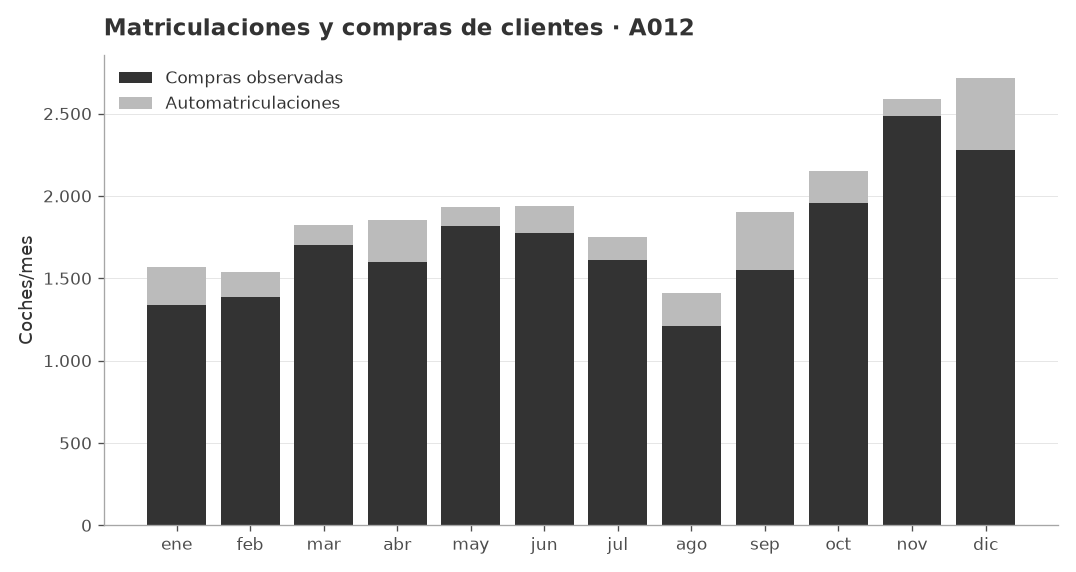

*Fuente: ventas_kaido_mensuales.csv; suma de canales y segmentos, A012.*

La altura completa son matriculaciones; solo la parte oscura son compras de clientes. Restar automatriculaciones no revela las ventas perdidas por falta de coches.

In [3]:
anual = ventas[ventas.anio.isin(["A011", "A012"])].groupby("anio")[[
    "unidades", "u_automatriculacion", "clientes"]].sum()
tabla(anual, "Kaido completo · compras observadas · coches/año", 0)
crecimiento = anual.loc["A012", "clientes"] / anual.loc["A011", "clientes"] - 1
comparable = ventas[ventas.segmento.ne("CSUV")].groupby("anio").clientes.sum()
crecimiento_comparable = comparable["A012"] / comparable["A011"] - 1
print(f"A012: {numero(anual.loc['A012', 'unidades'])} − "
      f"{numero(anual.loc['A012', 'u_automatriculacion'])} = {numero(anual.loc['A012', 'clientes'])}.")
print(f"Crecimiento total: {numero(100 * crecimiento, 2)} %; "
      f"sin el lanzamiento CSUV: {numero(100 * crecimiento_comparable, 2)} %.")

mensual_obs = ventas.query("anio == 'A012'").groupby("mes")[["clientes", "u_automatriculacion"]].sum()
fig, ax = plt.subplots()
ax.bar(MESES, mensual_obs.clientes, color=GRIS, label="Compras observadas")
ax.bar(MESES, mensual_obs.u_automatriculacion, bottom=mensual_obs.clientes,
       color="#BBBBBB", label="Automatriculaciones")
ax.set(title="Matriculaciones y compras de clientes · A012", ylabel="Coches/mes")
ax.legend()
figura(fig, "01_matriculaciones", "ventas_kaido_mensuales.csv; suma de canales y segmentos, A012.",
       "La altura completa son matriculaciones; solo la parte oscura son compras de clientes. "
       "Restar automatriculaciones no revela las ventas perdidas por falta de coches.")

In [4]:
display(Math(
    rf"g=\frac{{{nlatex(anual.loc['A012', 'clientes'])}}}"
    rf"{{{nlatex(anual.loc['A011', 'clientes'])}}}-1"
    rf"={nlatex(crecimiento, 4)}={nlatex(100*crecimiento, 2)}\,\%."))
explicar(
    f"El total crece un **{numero(100*crecimiento, 2)} %**, mientras que la gama sin CSUV "
    f"varía un **{numero(100*crecimiento_comparable, 2)} %**. Por tanto, el crecimiento "
    "del total no significa que los segmentos ya existentes estén creciendo en conjunto. "
    "Además, estas compras son operaciones realizadas: los datos no cuentan directamente "
    "a los clientes que no pudieron comprar por falta de coches.")

<IPython.core.display.Math object>

El total crece un **5,95 %**, mientras que la gama sin CSUV varía un **-0,15 %**. Por tanto, el crecimiento del total no significa que los segmentos ya existentes estén creciendo en conjunto. Además, estas compras son operaciones realizadas: los datos no cuentan directamente a los clientes que no pudieron comprar por falta de coches.

## 2. Estimación de la demanda mensual

### 2.1. Relación entre el mercado y las compras de Kaido

Denotemos por $I_{t,s}$ las matriculaciones de **todo el mercado** en un segmento.
No deben confundirse con $M_{t,s}$, que solo incluye Kaido. Para estimar cuántas
compras de Kaido corresponden a un volumen de mercado, usamos la relación

$$q_s=\frac{\sum_{t\in T} C_{t,s}}{\sum_{t\in T} I_{t,s}},$$

donde $T$ es el conjunto de meses elegidos como referencia. En los segmentos con
historia comparable se toman meses de los últimos doce disponibles y se excluyen
los marcados con incentivos, adelantos, caídas posteriores o subida del IVA.
Así se evita tomar una situación excepcional como nivel comercial habitual.

El cociente $q_s$ no tiene unidades. Tampoco es exactamente una cuota de
matriculaciones: su numerador contiene compras netas y su denominador,
matriculaciones del mercado. Si $q_t=C_t/I_t$, se puede escribir

$$q_s=\sum_{t\in T}\frac{I_t}{\sum_{u\in T}I_u}\,q_t.$$

Es una media ponderada de los cocientes mensuales: un mes con más mercado tiene
más peso. La media aritmética $\sum q_t/|T|$ daría el mismo peso a todos los meses.

In [5]:
meses_cuota = actual.copy()
meses_cuota["valido"] = ~meses_cuota[api_demanda.EVENTOS].fillna(0).gt(0).any(axis=1)
meses_cuota["ratio_mes_pct"] = 100 * meses_cuota.demanda_observada / meses_cuota.mercado
tabla(meses_cuota[["mes", "demanda_observada", "mercado", "valido", "ratio_mes_pct"]].set_index("mes"),
      f"{SEGMENTO_EJEMPLO} · qué meses A012 entran en la relación comercial", 2)
limpios = meses_cuota[meses_cuota.valido]
q = limpios.demanda_observada.sum() / limpios.mercado.sum()
media_simple = (limpios.demanda_observada / limpios.mercado).mean()
assert np.isclose(q, base["cuotas"][SEGMENTO_EJEMPLO])
print(f"q = {numero(limpios.demanda_observada.sum())} / {numero(limpios.mercado.sum())} "
      f"= {numero(q * 100, 3)} %.")
print(f"La media simple daría {numero(100 * media_simple, 3)} %: "
      "el cociente de sumas pondera cada mes por su mercado.")

MSUV · qué meses A012 entran en la relación comercial


,demanda_observada,mercado,valido,ratio_mes_pct
mes,,,,
1,515,10.270,True,"5,01"
2,642,10.710,True,"5,99"
3,688,14.140,True,"4,87"
4,660,13.678,True,"4,83"
5,609,15.116,True,"4,03"
6,551,15.075,True,"3,66"
7,568,15.237,True,"3,73"
8,420,9.433,True,"4,45"
9,446,11.133,True,"4,01"


q = 5.772 / 128.519 = 4,491 %.
La media simple daría 4,547 %: el cociente de sumas pondera cada mes por su mercado.


In [6]:
display(Math(
    rf"q_{{{SEGMENTO_EJEMPLO}}}="
    rf"\frac{{{nlatex(limpios.demanda_observada.sum())}}}"
    rf"{{{nlatex(limpios.mercado.sum())}}}={nlatex(q, 6)}."))
explicar(
    f"En los meses seleccionados se observan unas **{numero(1000*q, 1)} compras de "
    f"{SEGMENTO_EJEMPLO} por cada 1.000 matriculaciones de su mercado**. Si esa relación "
    "se mantuviera, bastaría multiplicar el mercado previsto por este cociente. "
    "La siguiente tarea es, por tanto, estimar el mercado del mes futuro.")

<IPython.core.display.Math object>

En los meses seleccionados se observan unas **44,9 compras de MSUV por cada 1.000 matriculaciones de su mercado**. Si esa relación se mantuviera, bastaría multiplicar el mercado previsto por este cociente. La siguiente tarea es, por tanto, estimar el mercado del mes futuro.

### 2.2. Variación interanual y logaritmo

Comparar enero con diciembre mezcla el cambio del mercado con la diferencia
habitual entre esos meses. Para reducir este efecto estacional, comparamos cada
mes con el **mismo mes del año anterior**, situado doce posiciones antes:

$$r_{t,s}=\frac{I_{t,s}}{I_{t-12,s}},\qquad
g_{t,s}=r_{t,s}-1.$$

Un cociente $r=1$ significa que no hay variación; $r>1$ indica aumento y $0<r<1$,
disminución. La regresión se aplica al logaritmo natural del cociente:

$$y_{t,s}=\log r_{t,s}.$$

El logaritmo transforma productos en sumas: $\log(ab)=\log a+\log b$. Esto permite
representar variaciones proporcionales mediante una suma de términos. Para volver
a la escala original se aplica la exponencial, que es su función inversa:

$$r=e^y,\qquad g=e^y-1,\qquad I_t=I_{t-12}e^y.$$

Solo para variaciones pequeñas se cumple aproximadamente $g\approx y$.
No debemos interpretar cualquier valor de $y$ directamente como un porcentaje.

In [7]:
mercado_anterior = float(mercado.loc[121, SEGMENTO_EJEMPLO])
mercado_actual = float(mercado.loc[133, SEGMENTO_EJEMPLO])
ratio_observado = mercado_actual / mercado_anterior
y_observado = np.log(ratio_observado)
display(Math(
    rf"r=\frac{{{nlatex(mercado_actual)}}}{{{nlatex(mercado_anterior)}}}"
    rf"={nlatex(ratio_observado, 4)},\quad "
    rf"y=\log({nlatex(ratio_observado, 4)})={nlatex(y_observado, 4)}."))
display(Math(
    rf"I_{{\mathrm{{ene\ A012}}}}={nlatex(mercado_anterior)}"
    rf"\,e^{{{nlatex(y_observado, 4)}}}\simeq {nlatex(mercado_actual)}\;\text{{coches}}."))
explicar(
    f"La variación observada de enero A012 respecto a enero A011 es "
    f"**{numero(100*(ratio_observado-1), 2)} %**. Las dos expresiones describen el mismo "
    "dato en escalas distintas; todavía no hemos hecho una previsión. Las pequeñas "
    "diferencias al sustituir los números mostrados se deben al redondeo de presentación.")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

La variación observada de enero A012 respecto a enero A011 es **-9,57 %**. Las dos expresiones describen el mismo dato en escalas distintas; todavía no hemos hecho una previsión. Las pequeñas diferencias al sustituir los números mostrados se deben al redondeo de presentación.

### 2.3. Regresión lineal y estimación de coeficientes

Una regresión lineal aproxima una variable mediante una combinación de otras.
Para una observación $i$ —un mes de un segmento— escribimos

$$y_i=\beta_0+\beta_1x_{i,1}+\cdots+\beta_px_{i,p}+\varepsilon_i.$$

$y_i$ es el logaritmo interanual definido antes; las $x_{i,k}$ son cantidades
conocidas; los coeficientes $\beta_k$ son los números que debemos estimar.
El término $\varepsilon_i$ representa lo que esa combinación no explica.
El **intercepto** $\beta_0$ permite un cambio de fondo incluso cuando todas las
otras variables transformadas valen cero.

Estudiaremos primero el candidato `conf_intercepto`. Sus variables son:

| Término | Valor que entra en la regresión |
|---|---|
| Intercepto | $1$ |
| Días laborables $L_t$ | $\log(L_t/L_{t-12})$ |
| Semana Santa | Diferencia del indicador entre $t$ y $t-12$ |
| Cada acontecimiento especial | Diferencia interanual de su indicador |
| Confianza del consumidor $K_t$ | $K_{t-3}-K_{t-15}$ |

Un indicador vale uno cuando se registra el acontecimiento y cero cuando no.
Su diferencia puede ser $-1$, $0$ o $1$. La confianza se retrasa tres meses:
para enero se utiliza octubre. En una previsión al cierre A012, desde abril A013
el dato retrasado ya sería futuro. El escenario central —los supuestos de
referencia del modelo— lo sustituye por el
último valor conocido, diciembre A012. El calendario A013 sí está disponible;
los acontecimientos futuros no conocidos se fijan en cero en la previsión operativa.

Para estimar $\beta$, cada mes-segmento aporta una ecuación. Al apilarlas obtenemos
$\mathbf y\approx X\boldsymbol\beta$. Generalmente no existe una solución exacta.
Los **mínimos cuadrados ponderados** eligen la que minimiza

$$\sum_i w_i(y_i-\mathbf x_i^\mathsf{T}\boldsymbol\beta)^2,
\qquad w_i=\sqrt{I_{i-12}}.$$

El cuadrado penaliza errores de ambos signos; el peso concede más influencia a
mercados grandes sin hacerla directamente proporcional a su tamaño. El proyecto
usa coeficientes comunes para los segmentos, conserva observaciones con mercado
anterior de al menos 200 coches y mercado actual positivo, y comienza en $t=16$
para disponer de las variables retrasadas. Las columnas enteramente nulas se omiten.

**Aplicación.** Construimos la matriz del ajuste hasta A012. Multiplicar cada fila
de $X$ y cada valor de $y$ por $\sqrt{w_i}$ convierte el problema ponderado en uno
de mínimos cuadrados ordinarios, que resolvemos con `lstsq`.

In [8]:
modelo = "conf_intercepto"
filas_ajuste = []
for t in range(16, 145):
    variables = api_demanda._fila_diseno(calendario, t, 144, modelo)
    for segmento in SEGMENTOS:
        anterior_mercado = mercado.loc[t - 12, segmento]
        actual_mercado = mercado.loc[t, segmento]
        if anterior_mercado >= 200 and actual_mercado > 0:
            filas_ajuste.append({**variables,
                                 "y": np.log(actual_mercado / anterior_mercado),
                                 "peso": np.sqrt(anterior_mercado)})
muestra = pd.DataFrame(filas_ajuste).dropna()
columnas = [c for c in muestra if c not in ["y", "peso"] and muestra[c].abs().sum() > 0]
X, y = muestra[columnas].to_numpy(), muestra.y.to_numpy()
raiz_peso = np.sqrt(muestra.peso.to_numpy())
coeficientes = np.linalg.lstsq(X * raiz_peso[:, None], y * raiz_peso, rcond=None)[0]
beta = pd.Series(coeficientes, index=columnas)
assert np.allclose(beta, api_demanda._ajustar_mercado(mercado, calendario, 144, modelo))
tabla(beta.to_frame("Coeficiente estimado"), "Regresión conjunta hasta A012", 5)
explicar(
    f"Se ajustan **{X.shape[1]} coeficientes con {X.shape[0]} observaciones**. "
    "Cada coeficiente multiplica la variable transformada de su fila: por ejemplo, "
    "el de confianza corresponde a un punto de cambio interanual del indicador retrasado. "
    "El ajuste identifica asociaciones históricas; no demuestra que intervenir en una "
    "variable produzca por sí solo ese efecto.")

Regresión conjunta hasta A012


,Coeficiente estimado
intercepto,"0,01535"
dias_laborables,"0,76392"
semana_santa,"-0,02006"
incentivo_publico,"0,11860"
adelanto_compras,"0,23551"
caida_tras_adelanto,"-0,05329"
subida_iva,"0,26484"
confianza_consumidor,"0,00957"


Se ajustan **8 coeficientes con 762 observaciones**. Cada coeficiente multiplica la variable transformada de su fila: por ejemplo, el de confianza corresponde a un punto de cambio interanual del indicador retrasado. El ajuste identifica asociaciones históricas; no demuestra que intervenir en una variable produzca por sí solo ese efecto.

### 2.4. Sustitución en la ecuación de previsión

Una vez estimados los coeficientes, prever un mes consiste en sustituir sus
variables en la ecuación. El símbolo $\widehat{\ }$ distingue una estimación
de una cantidad observada:

$$\widehat y_t=\sum_{k=0}^p\widehat\beta_kx_{t,k},\qquad
\widehat I_{t,s}=I_{t-12,s}e^{\widehat y_t},\qquad
\widehat D^{\,bruta}_{t,s}=q_s\widehat I_{t,s}.$$

$\widehat D^{\,bruta}$ es la previsión de compradores antes de las correcciones
que estudiaremos después. Puesto que los coeficientes y las variables son comunes,
el factor de crecimiento mensual estimado es común a los segmentos; sus cantidades
difieren por el mercado del año anterior y por su relación comercial $q_s$.

**Aplicación.** Calculamos enero A013. La última columna de la tabla contiene
los sumandos de $\widehat y_t$. Un coeficiente no contribuye a ese mes si la
variable por la que se multiplica es cero.

Sustitución de enero A013 en la regresión


,Variable transformada,Coeficiente,Producto
intercepto,"1,00000","0,01535","0,01535"
dias_laborables,"-0,04652","0,76392","-0,03554"
semana_santa,"0,00000","-0,02006","-0,00000"
incentivo_publico,"0,00000","0,11860","0,00000"
adelanto_compras,"0,00000","0,23551","0,00000"
caida_tras_adelanto,"0,00000","-0,05329","-0,00000"
subida_iva,"0,00000","0,26484","0,00000"
confianza_consumidor,"-19,70000","0,00957","-0,18860"


<IPython.core.display.Math object>

<IPython.core.display.Math object>

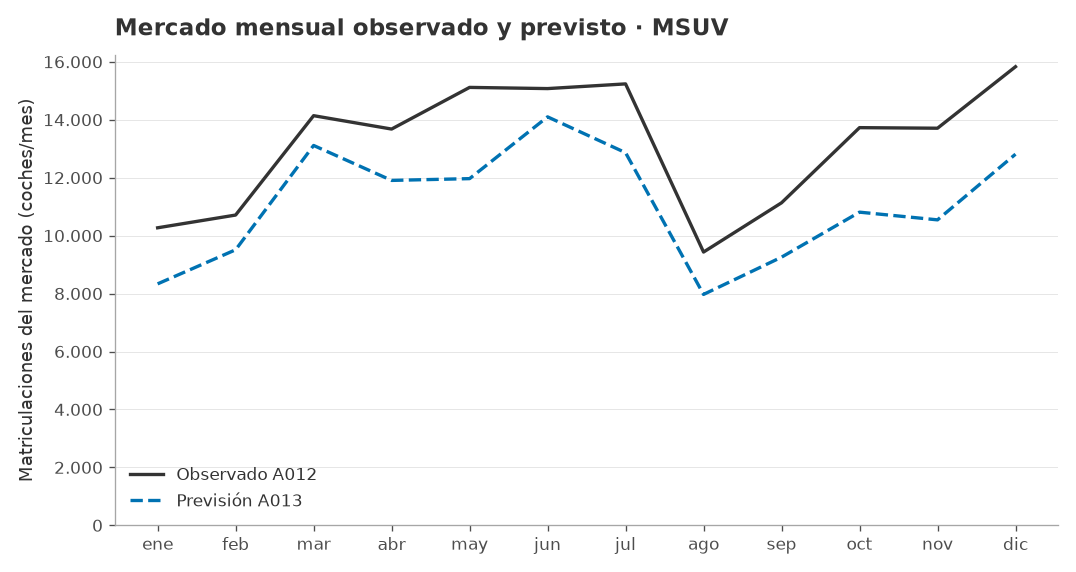

*Fuente: mercado_mensual.csv, economía y calendario; regresión hasta A012.*

En enero el cambio estimado es -18,84 %. La curva A013 se obtiene repitiendo la sustitución en cada mes. El perfil mensual conserva como referencia el mercado del mismo mes de A012; no es una recta en coches.

In [9]:
x_enero = pd.Series(api_demanda._fila_diseno(calendario, 145, 144, modelo)).reindex(beta.index)
desglose = pd.DataFrame({"Variable transformada": x_enero, "Coeficiente": beta,
                        "Producto": x_enero * beta})
y_enero = desglose.Producto.sum()
ancla = mercado.loc[133, SEGMENTO_EJEMPLO]
mercado_enero = ancla * np.exp(y_enero)
tabla(desglose, "Sustitución de enero A013 en la regresión", 5)
display(Math(
    rf"\widehat I_{{\mathrm{{ene}}}}={nlatex(ancla)}"
    rf"e^{{{nlatex(y_enero, 5)}}}={nlatex(mercado_enero, 2)}\;\text{{coches}}."))
display(Math(
    rf"\widehat D^{{\,bruta}}_{{\mathrm{{ene}}}}="
    rf"{nlatex(mercado_enero, 2)}\cdot {nlatex(q, 6)}"
    rf"={nlatex(mercado_enero*q, 2)}\;\text{{compradores}}."))
assert np.isclose(mercado_enero, base["mercado_prevision"].loc[145, SEGMENTO_EJEMPLO])

fig, ax = plt.subplots()
ax.plot(MESES, mercado.loc[133:144, SEGMENTO_EJEMPLO], color=GRIS, label="Observado A012")
ax.plot(MESES, base["mercado_prevision"][SEGMENTO_EJEMPLO], color=AZUL,
        linestyle="--", label="Previsión A013")
ax.set(title=f"Mercado mensual observado y previsto · {SEGMENTO_EJEMPLO}",
       ylabel="Matriculaciones del mercado (coches/mes)", ylim=(0, None))
ax.legend()
figura(fig, "03_regresion", "mercado_mensual.csv, economía y calendario; regresión hasta A012.",
       f"En enero el cambio estimado es {numero(100*np.expm1(y_enero), 2)} %. "
       "La curva A013 se obtiene repitiendo la sustitución en cada mes. El perfil mensual "
       "conserva como referencia el mercado del mismo mes de A012; no es una recta en coches.")

### 2.5. Errores de previsión y validación temporal

Una fórmula que ajusta el pasado no necesariamente predice bien. Para evaluar
una previsión necesitamos un periodo cuyo dato real no haya intervenido en su
estimación. Si $\widehat D_t$ es la previsión y $C_t$ las compras observadas,
definimos $e_t=\widehat D_t-C_t$. Así, $e_t>0$ significa sobreprevisión.

En $n$ meses, el **sesgo** y el **error absoluto medio** son

$$\operatorname{sesgo}=\frac1n\sum_te_t,\qquad
MAE=\frac1n\sum_t|e_t|.$$

El sesgo conserva el signo: errores positivos y negativos pueden compensarse.
El MAE mide magnitud sin compensación. Ambos se expresan en coches por mes.
Para comparar el error con el volumen observado se utiliza

$$WAPE=\frac{\sum_t|e_t|}{\sum_t C_t}.$$

Por ejemplo, un WAPE del 20 % significa que la suma de errores absolutos equivale
al 20 % de las compras observadas; no significa que se acierte en el 80 % de los meses.

El proyecto compara cuatro candidatos: repetir el patrón anual de compras;
regresión de confianza sin intercepto; la misma regresión con intercepto;
y regresión que además incorpora paro y crédito. Cada candidato prevé A009,
A010 y A011 entrenando solo con años anteriores. Se elige el menor WAPE conjunto
de meses y segmentos, sin CSUV. **A012 no decide el ganador.**

Validación temporal: nunca entrenar con el año que se está prediciendo


,Último año de entrenamiento,Año previsto,Uso
0,A008,A009,Selección
1,A009,A010,Selección
2,A010,A011,Selección / verificar sesgo
3,A011,A012,Evaluación retrospectiva


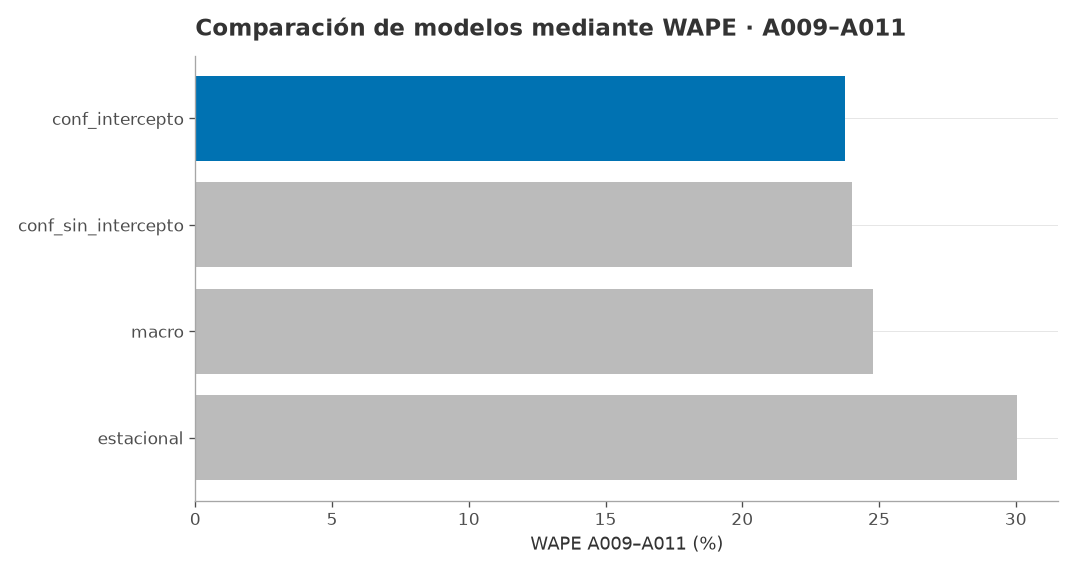

*Fuente: demanda.ipynb; errores fuera de muestra, seis segmentos sin CSUV.*

Se selecciona conf_intercepto, con WAPE 23,77 %. Se suman errores absolutos por mes y segmento antes de dividir: no se cancelan entre segmentos.

In [10]:
tabla(pd.DataFrame({"Último año de entrenamiento": ["A008", "A009", "A010", "A011"],
                    "Año previsto": ["A009", "A010", "A011", "A012"],
                    "Uso": ["Selección", "Selección", "Selección / verificar sesgo", "Evaluación retrospectiva"]}),
      "Validación temporal: nunca entrenar con el año que se está prediciendo", 0)
seleccion = base["seleccion"].sort_values("wape").set_index("modelo")
fig, ax = plt.subplots()
ax.barh(seleccion.index, 100 * seleccion.wape,
        color=[AZUL if nombre == modelo else "#BBBBBB" for nombre in seleccion.index])
ax.invert_yaxis()
ax.set(title="Comparación de modelos mediante WAPE · A009–A011", xlabel="WAPE A009–A011 (%)")
figura(fig, "04_seleccion", "demanda.ipynb; errores fuera de muestra, seis segmentos sin CSUV.",
       f"Se selecciona {modelo}, con WAPE {numero(100 * seleccion.loc[modelo, 'wape'], 2)} %. "
       "Se suman errores absolutos por mes y segmento antes de dividir: no se cancelan entre segmentos.")

La selección anterior respalda el candidato con intercepto que acabamos de
desarrollar. Veamos ahora qué ocurre al prever A012 desde el cierre A011. Esta
es una evaluación retrospectiva separada; los coeficientes se vuelven a estimar
con datos disponibles en ese origen, no con los coeficientes hasta A012 de
nuestro ejemplo anterior.

La siguiente tabla permite reconstruir las tres medidas mes a mes. La comparación
se hace con compras observadas, no con una demanda histórica perdida que los
datos no permiten conocer directamente.

MSUV · previsión al cierre A011 frente a A012 · coches


,observado,prevision,error,error_absoluto
Mes,,,,
ene,"515,0","577,2","62,2","62,2"
feb,"642,0","575,5","-66,5","66,5"
mar,"688,0","666,0","-22,0","22,0"
abr,"660,0","601,0","-59,0","59,0"
may,"609,0","711,8","102,8","102,8"
jun,"551,0","704,7","153,7","153,7"
jul,"568,0","828,7","260,7","260,7"
ago,"420,0","388,1","-31,9","31,9"
sep,"446,0","451,1","5,1","5,1"


MAE = 1.391,4 / 12 = 116,0 coches/mes.
Sesgo = -18,5 coches/mes; WAPE = 18,6 %.


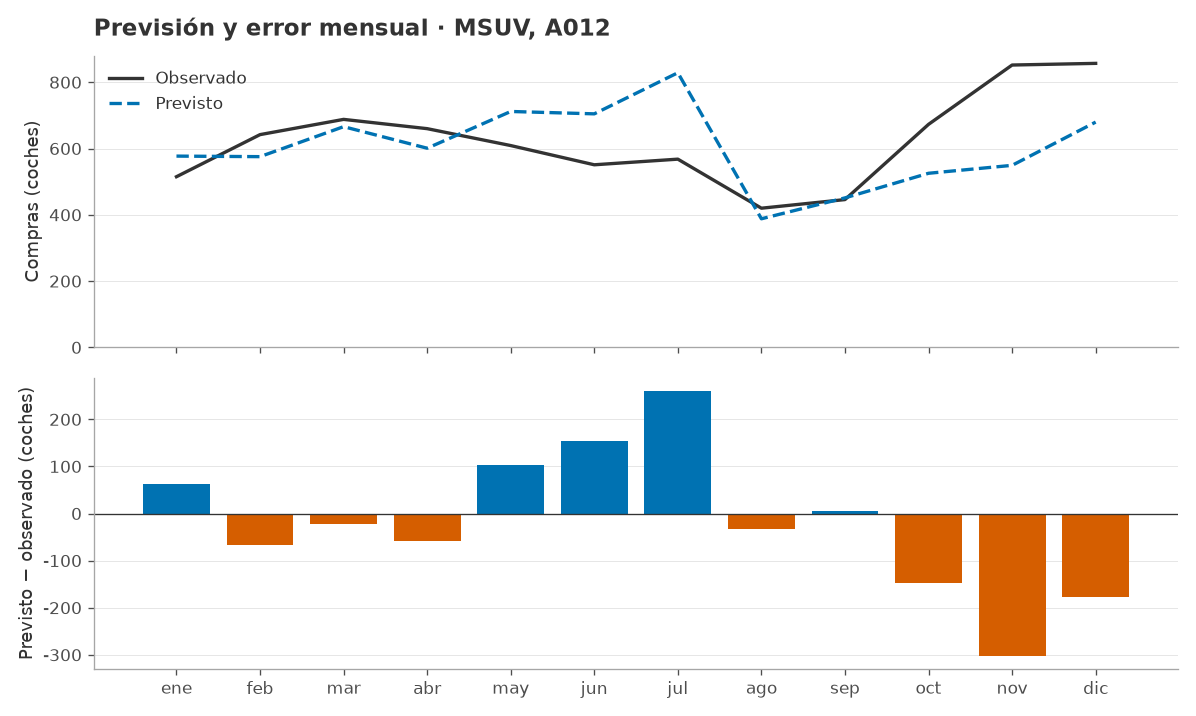

*Fuente: ventas del caso y previsión operativa de demanda.ipynb; A012.*

Barras positivas significan sobreprevisión; negativas, infraprevisión. El sesgo puede ser pequeño por compensación y coexistir con un MAE grande.

In [11]:
errores_a012 = base["errores_todos"].query("fase == 'retrospectiva_A012'")
errores_ejemplo = errores_a012.query("segmento == @SEGMENTO_EJEMPLO").sort_values("t").copy()
errores_ejemplo["Mes"] = MESES
errores_ejemplo["error_absoluto"] = errores_ejemplo.error.abs()
tabla(errores_ejemplo.set_index("Mes")[["observado", "prevision", "error", "error_absoluto"]],
      f"{SEGMENTO_EJEMPLO} · previsión al cierre A011 frente a A012 · coches", 1)
mae = errores_ejemplo.error_absoluto.mean()
sesgo = errores_ejemplo.error.mean()
wape = errores_ejemplo.error_absoluto.sum() / errores_ejemplo.observado.sum()
print(f"MAE = {numero(errores_ejemplo.error_absoluto.sum(), 1)} / 12 = {numero(mae, 1)} coches/mes.")
print(f"Sesgo = {numero(sesgo, 1)} coches/mes; WAPE = {numero(100*wape, 1)} %.")

fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ejes[0].plot(MESES, errores_ejemplo.observado, color=GRIS, label="Observado")
ejes[0].plot(MESES, errores_ejemplo.prevision, color=AZUL, linestyle="--", label="Previsto")
ejes[0].set(title=f"Previsión y error mensual · {SEGMENTO_EJEMPLO}, A012", ylabel="Compras (coches)", ylim=(0, None))
ejes[0].legend()
ejes[1].bar(MESES, errores_ejemplo.error, color=np.where(errores_ejemplo.error >= 0, AZUL, NARANJA))
ejes[1].axhline(0, color=GRIS, lw=.8)
ejes[1].set_ylabel("Previsto − observado (coches)")
figura(fig, "05_errores", "ventas del caso y previsión operativa de demanda.ipynb; A012.",
       "Barras positivas significan sobreprevisión; negativas, infraprevisión. "
       "El sesgo puede ser pequeño por compensación y coexistir con un MAE grande.")

In [12]:
fila_error = errores_ejemplo.iloc[0]
display(Math(
    rf"e_{{\mathrm{{ene}}}}={nlatex(fila_error.prevision, 1)}"
    rf"-{nlatex(fila_error.observado)}={nlatex(fila_error.error, 1)}\;\text{{coches}}."))
explicar(
    f"El MAE de {numero(mae, 1)} coches/mes es mayor que el valor absoluto del sesgo "
    f"({numero(abs(sesgo), 1)}). Por tanto, resumir esta previsión solo con su sesgo "
    "ocultaría parte de los errores mensuales. Cuando se suman segmentos antes de "
    "calcular el error absoluto también puede haber compensaciones: por eso la selección "
    "evalúa los errores de cada segmento antes de agregarlos.")

<IPython.core.display.Math object>

El MAE de 116,0 coches/mes es mayor que el valor absoluto del sesgo (18,5). Por tanto, resumir esta previsión solo con su sesgo ocultaría parte de los errores mensuales. Cuando se suman segmentos antes de calcular el error absoluto también puede haber compensaciones: por eso la selección evalúa los errores de cada segmento antes de agregarlos.

### 2.6. Corrección del sesgo y de las compras adelantadas

Hay dos ajustes diferentes. El primero corrige una desviación de escala que
persiste en las previsiones de un segmento. Se propone el factor

$$f_s=\frac{\sum C_{t,s}}{\sum\widehat D_{t,s}}.$$

Si se prevé sistemáticamente demasiado, $f_s<1$; si se prevé demasiado poco,
$f_s>1$. En el proyecto se estima con los errores de A009 y A010, solo cuando
el sesgo tiene el mismo signo en ambos años, y se limita al intervalo $[0{,}8;1{,}2]$.
Se acepta si reduce el MAE de A011 y se mantiene una señal de sesgo en los dos años
más recientes de esa validación. Se conserva el factor que se verificó, sin
reestimarlo con A012.

El segundo ajuste representa **compras adelantadas**: compras efectuadas en A012
que, según una hipótesis de referencia, habrían ocurrido más tarde. No conocemos
la identidad de esos clientes. Estimamos el exceso de noviembre–diciembre sobre
dos referencias estacionales, A009 y A010, adaptadas al nivel de A012.

Para una referencia $a$, sean $B_a$ sus compras anteriores al pico y $P_a$ sus
compras durante los meses del pico. Definimos

$$k_a=\frac{B_{A012}}{B_a},\qquad
P_a^{ref}=k_aP_a,\qquad
E_a=\max(0,P_{A012}-P_a^{ref}).$$

El factor $k_a$ iguala el nivel anterior al episodio. Solo después se compara
el pico. El adelanto central $E_s$ es la media de los dos excesos. El mínimo y
máximo expresan sensibilidad a la referencia, no un intervalo de confianza.

MSUV · referencias escaladas al nivel A012


,Base anterior al pico (coches),Factor de nivel,Pico esperado (coches),Pico observado (coches),Exceso estimado (coches)
Referencia,,,,,
A009,5.318,"1,09","985,52",1.709,"723,48"
A010,4.889,"1,18","1.901,96",1.709,"0,00"


Adelanto central = media de los dos excesos = 361,7 coches.


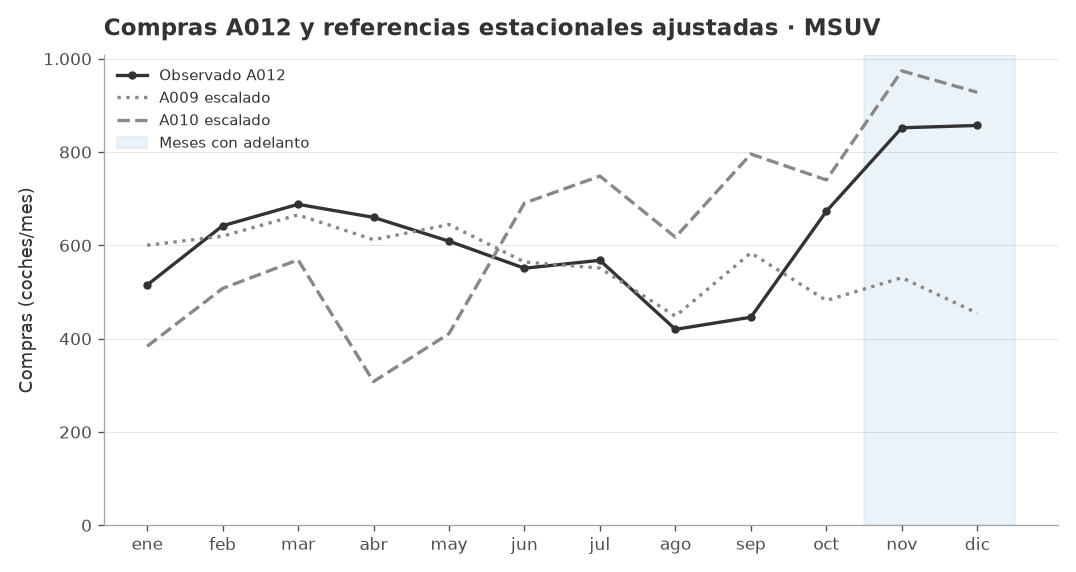

*Fuente: ventas y flags de economia_eventos_mensuales.csv; método de datos.ipynb, A009–A012.*

Se adapta cada referencia con compras anteriores al pico de A012 / compras del mismo periodo de referencia. El exceso depende de esa referencia: es una estimación, no compradores identificados ni un intervalo de confianza.

In [13]:
# Reconstruimos el adelanto del segmento frente a cada referencia estacional.
actual = serie.query("anio == 'A012' and segmento == @SEGMENTO_EJEMPLO")
meses_pico = actual.loc[actual.adelanto_compras.eq(1), "mes"].tolist()
primer_pico = min(meses_pico)
nivel_actual = actual.loc[actual.mes.lt(primer_pico), "demanda_observada"].sum()
compras_pico = actual.loc[actual.mes.isin(meses_pico), "demanda_observada"].sum()
filas, referencias = [], {}
for anio in ["A009", "A010"]:
    ref = serie.query("anio == @anio and segmento == @SEGMENTO_EJEMPLO").set_index("mes")
    nivel_ref = ref.loc[ref.index < primer_pico, "demanda_observada"].sum()
    escala = nivel_actual / nivel_ref
    referencias[anio] = ref.demanda_observada * escala
    normal_pico = referencias[anio].loc[meses_pico].sum()
    filas.append({"Referencia": anio, "Base anterior al pico (coches)": nivel_ref,
                  "Factor de nivel": escala, "Pico esperado (coches)": normal_pico,
                  "Pico observado (coches)": compras_pico,
                  "Exceso estimado (coches)": max(0, compras_pico - normal_pico)})
adelanto_ejemplo = pd.DataFrame(filas).set_index("Referencia")
estimado = adelanto_ejemplo["Exceso estimado (coches)"].mean()
adelanto_api = base["adelantos"].set_index("segmento").loc[SEGMENTO_EJEMPLO, "adelanto_central"]
assert np.isclose(estimado, adelanto_api)
tabla(adelanto_ejemplo, f"{SEGMENTO_EJEMPLO} · referencias escaladas al nivel A012", 2)
print(f"Adelanto central = media de los dos excesos = {numero(estimado, 1)} coches.")

fig, ax = plt.subplots()
ax.plot(MESES, actual.sort_values("mes").demanda_observada, color=GRIS, marker="o", label="Observado A012")
for anio, referencia in referencias.items():
    ax.plot(MESES, referencia, linestyle=":" if anio == "A009" else "--",
            color="#888888", label=f"{anio} escalado")
ax.axvspan(primer_pico - 1.5, 11.5, color=AZUL, alpha=.08, label="Meses con adelanto")
ax.set(title=f"Compras A012 y referencias estacionales ajustadas · {SEGMENTO_EJEMPLO}", ylabel="Compras (coches/mes)", ylim=(0, None))
ax.legend(fontsize=9)
figura(fig, "02_adelanto", "ventas y flags de economia_eventos_mensuales.csv; método de datos.ipynb, A009–A012.",
       "Se adapta cada referencia con compras anteriores al pico de A012 / compras del mismo periodo de referencia. "
       "El exceso depende de esa referencia: es una estimación, no compradores identificados ni un intervalo de confianza.")

En el escenario central se reparte $E_s$ entre enero, febrero y marzo A013.
La previsión completa para uno de esos meses es

$$\widehat D_{t,s}=\max\left(0,\widehat I_{t,s}q_sf_s-\frac{E_s}{3}\right).$$

Para los demás meses no se resta $E_s/3$. La función máximo evita compradores
negativos: si un mes no permite descontar su parte completa, se registra cuánto
queda sin aplicar. El registro de cantidades descontadas se denomina *ledger*
en los archivos del proyecto.

**Aplicación.** Completamos la cuenta de enero iniciada en el apartado 2.4.
En la tabla, cada fila parte de la anterior; el descuento es una cantidad de
coches, mientras que el factor de sesgo es un multiplicador sin unidades.

In [14]:
mercado_enero = base["mercado_prevision"].loc[145, SEGMENTO_EJEMPLO]
factor_sesgo = base["_contexto"]["factores_sesgo"][SEGMENTO_EJEMPLO]
antes_ledger = mercado_enero * q * factor_sesgo
descuento_enero = min(antes_ledger, adelanto_api / 3)
demanda_enero = max(0, antes_ledger - descuento_enero)
assert np.isclose(demanda_enero, base["prevision"].loc[145, SEGMENTO_EJEMPLO])
tabla(pd.DataFrame({"Coches": [mercado_enero, mercado_enero * q,
                               antes_ledger, -descuento_enero, demanda_enero]},
                   index=["Mercado previsto", "Mercado × relación comercial",
                          "Tras factor de sesgo", "Descuento del adelanto", "Demanda central final"]),
      f"Cuenta completa de enero A013 · {SEGMENTO_EJEMPLO}", 2)
print(f"Factor de sesgo: {numero(factor_sesgo, 3)}. Se verificó antes de A012; "
      "no se impone que todos los segmentos tengan sesgo cero.")
print("El ledger es el registro de adelantos: se descuenta una sola vez, aquí en enero–marzo. "
      "Si no cabe todo sin demanda negativa, se informa de lo no aplicado.")
tabla(base["sesgo"].set_index("segmento")[["factor_A013", "aplicar"]],
      "Correcciones aceptadas tras verificar A011", 3)

Cuenta completa de enero A013 · MSUV


,Coches
Mercado previsto,"8.334,77"
Mercado × relación comercial,"374,33"
Tras factor de sesgo,"374,33"
Descuento del adelanto,"-120,58"
Demanda central final,"253,75"


Factor de sesgo: 1,000. Se verificó antes de A012; no se impone que todos los segmentos tengan sesgo cero.
El ledger es el registro de adelantos: se descuenta una sola vez, aquí en enero–marzo. Si no cabe todo sin demanda negativa, se informa de lo no aplicado.
Correcciones aceptadas tras verificar A011


,factor_A013,aplicar
segmento,,
B,"1,000",False
C,"1,000",False
MD,"0,844",True
SSUV,"1,200",True
MSUV,"1,000",False
S,"1,000",False


In [15]:
display(Math(
    rf"\widehat D_{{\mathrm{{ene}},{SEGMENTO_EJEMPLO}}}="
    rf"\max\left(0,{nlatex(mercado_enero, 2)}\cdot {nlatex(q, 6)}"
    rf"\cdot {nlatex(factor_sesgo, 3)}-\frac{{{nlatex(adelanto_api, 2)}}}{{3}}\right)"
    rf"={nlatex(demanda_enero, 2)}."))
explicar(
    f"La previsión central de enero queda en **{numero(demanda_enero, 2)} compradores "
    f"de {SEGMENTO_EJEMPLO}**. El resultado combina una previsión del mercado, una "
    "relación comercial histórica y dos ajustes con significados distintos. No es "
    "un recuento de futuros clientes identificados. Al simular operaciones se redondeará "
    "a coches enteros.")

<IPython.core.display.Math object>

La previsión central de enero queda en **253,75 compradores de MSUV**. El resultado combina una previsión del mercado, una relación comercial histórica y dos ajustes con significados distintos. No es un recuento de futuros clientes identificados. Al simular operaciones se redondeará a coches enteros.

**El caso de CSUV.** Al lanzarse en agosto A012, no dispone de una serie de ventas
comparable a la de los otros segmentos. No sería correcto interpretar los ceros
previos al lanzamiento como meses de demanda nula de un producto disponible.
Para estimar $q$ se excluye agosto, parcial, y se utilizan septiembre–diciembre,
ajustando el posible adelanto. Este último se aproxima con el exceso estacional
del mercado CSUV, no con ventas propias inexistentes en A009–A010.

La tabla contrasta esa elección con usar solo septiembre–octubre. Se trata de
una sensibilidad de la previsión, no de una validación histórica del lanzamiento.

In [16]:
csuv = base["diagnostico_csuv"][["mes", "demanda_observada", "observado_ajustado", "mercado"]]
tabla(csuv.set_index("mes"), "CSUV · meses usados de A012 · coches", 1)
tabla(base["sensibilidad_csuv"].set_index("metodo"), "CSUV · dos anclas posibles", 3)
print("CSUV empieza en agosto A012: se excluye ese mes parcial y se usan septiembre–diciembre, "
      "ajustando el posible adelanto. No se proyectan los ceros anteriores al lanzamiento.")
print("Estas alternativas muestran cuánto depende la estimación de los pocos meses disponibles.")

CSUV · meses usados de A012 · coches


,demanda_observada,observado_ajustado,mercado
mes,,,
9,180,"180,0",11.006
10,268,"268,0",13.179
11,351,"351,0",13.528
12,368,"368,0",13.419


CSUV · dos anclas posibles


,cuota,demanda_anual_antes_ledger
metodo,,
sept-oct sin adelantos,"0,019","2.743,536"
sept-dic ajustados por ledger,"0,023","3.380,312"


CSUV empieza en agosto A012: se excluye ese mes parcial y se usan septiembre–diciembre, ajustando el posible adelanto. No se proyectan los ceros anteriores al lanzamiento.
Estas alternativas muestran cuánto depende la estimación de los pocos meses disponibles.


## 3. Balance de existencias y cálculo de pedidos

### 3.1. Disponibilidad, ventas y existencias finales

La previsión anterior estima compras deseadas. Para calcular ventas efectivas
debemos añadir la restricción física del inventario. Consideremos un segmento
y omitamos el subíndice $s$ para simplificar. En el mes $t$:

- $S_{t-1}$ es el stock al final del mes anterior;
- $L_t$ son las llegadas al comienzo del mes;
- $D_t$ es la demanda de ese mes;
- $V_t$ son las ventas realizadas.

Todos son números de coches. Los disponibles son $U_t=S_{t-1}+L_t$. Sin recibir
coches adicionales durante el mes, el balance es

$$V_t=\min(D_t,U_t),\qquad
S_t=U_t-V_t,\qquad P_t=D_t-V_t.$$

$P_t$ mide compras perdidas. Si $D_t\le U_t$, se atiende toda la demanda y puede
quedar stock. Si $D_t>U_t$, se vende todo lo disponible y se pierden $D_t-U_t$
compras. Estas ecuaciones conservan los coches: ninguno aparece o desaparece
fuera de las llegadas y ventas.

**Aplicación.** El stock inicial procede de diciembre A012. Las llegadas de enero
y febrero ya habrían sido encargadas antes del inicio de A013. Como no disponemos
de esos pedidos, el modelo las aproxima con el promedio redondeado de entradas
a la red (*wholesale*) de los últimos seis meses activos. Es una hipótesis de
inicialización, no un dato de pedidos observados.

In [17]:
stock_inicial = api_sim._stock_inicial(datos).sum(axis=0)
compromisos = api_sim._compromisos(datos, meses_pipeline=6, multiplicador=1.)
demanda_12 = base["prevision"].to_numpy()
demanda_entera = np.rint(demanda_12).astype(int)
disponibles_enero = stock_inicial[j] + compromisos[j]
ventas_enero_manual = min(demanda_entera[0, j], disponibles_enero)
stock_enero_manual = disponibles_enero - ventas_enero_manual
tabla(pd.DataFrame({"Coches": [stock_inicial[j], compromisos[j], disponibles_enero,
                               demanda_entera[0,j], ventas_enero_manual, stock_enero_manual]},
                   index=["Stock diciembre A012", "Llegadas enero A013 (estimadas)",
                          "Disponibles", "Demanda central redondeada", "Ventas", "Stock final"]),
      f"Balance de enero A013 · {SEGMENTO_EJEMPLO}", 0)

# SSUV permite observar la otra rama del mínimo con datos del mismo modelo.
k_ssuv = SEGMENTOS.index("SSUV")
stock_ssuv_enero = max(0, stock_inicial[k_ssuv] + compromisos[k_ssuv] - demanda_entera[0,k_ssuv])
disponibles_ssuv = stock_ssuv_enero + compromisos[k_ssuv]
ventas_ssuv = min(demanda_entera[1,k_ssuv], disponibles_ssuv)
display(Math(
    rf"V_{{\mathrm{{feb,SSUV}}}}=\min\left({nlatex(demanda_entera[1,k_ssuv])},"
    rf"{nlatex(stock_ssuv_enero)}+{nlatex(compromisos[k_ssuv])}\right)={nlatex(ventas_ssuv)}."))
explicar(
    f"En enero, {SEGMENTO_EJEMPLO} conserva {numero(stock_enero_manual)} coches. "
    f"En cambio, SSUV dispone de {numero(disponibles_ssuv)} para una demanda de "
    f"{numero(demanda_entera[1,k_ssuv])} en febrero: pierde "
    f"**{numero(demanda_entera[1,k_ssuv]-ventas_ssuv)} compras**. Incluso si la previsión "
    "central se cumple exactamente, las llegadas comprometidas pueden no ser suficientes.")

Balance de enero A013 · MSUV


,Coches
Stock diciembre A012,536
Llegadas enero A013 (estimadas),576
Disponibles,1.112
Demanda central redondeada,254
Ventas,254
Stock final,858


<IPython.core.display.Math object>

En enero, MSUV conserva 858 coches. En cambio, SSUV dispone de 411 para una demanda de 500 en febrero: pierde **89 compras**. Incluso si la previsión central se cumple exactamente, las llegadas comprometidas pueden no ser suficientes.

### 3.2. Plazo de entrega y dispersión del error acumulado

Un pedido decidido en enero llega en abril: el plazo es de tres meses. Al decidir
no basta con mirar el stock de hoy. Debemos proyectar el que quedará tras la demanda
y las llegadas intermedias. Además, la previsión puede fallar durante ese plazo.

Para medir esa incertidumbre se suman los errores de tres meses consecutivos:

$$u_i=\frac{e_i+e_{i+1}+e_{i+2}}
{\widehat D_i+\widehat D_{i+1}+\widehat D_{i+2}}.$$

$u_i$ es un error relativo, sin unidades. El denominador es ahora la **previsión**,
no las compras observadas utilizadas en el WAPE. La media $\bar u$ describe su
desviación de nivel. Para medir cuánto varía alrededor de esa media usamos la
desviación típica muestral:

$$\sigma_{3,rel}=
\sqrt{\frac{1}{n-1}\sum_{i=1}^n(u_i-\bar u)^2}.$$

Restar la media centra los errores; elevar al cuadrado evita cancelaciones;
la raíz devuelve la medida a la escala de las proporciones. Se calculan ventanas
móviles dentro de cada año A009–A011, sin unir años de validación distintos.
Las ventanas se solapan: esta desviación es una calibración empírica, no una
muestra de observaciones independientes para construir un intervalo de confianza.

In [18]:
sigma3 = base["sigma3_rel"].reindex(SEGMENTOS).to_numpy()

In [19]:
ventanas = []
for origen, grupo in base["errores"].query("segmento == @SEGMENTO_EJEMPLO").groupby("origen"):
    grupo = grupo.sort_values("t")
    for inicio in range(len(grupo) - 2):
        v = grupo.iloc[inicio:inicio + 3]
        ventanas.append({"Año previsto": f"A{origen//12 + 1:03d}",
                         "Inicio (mes)": int((v.t.iloc[0] - 1) % 12 + 1),
                         "Previsto 3 meses": v.prevision.sum(), "Error 3 meses": v.error.sum(),
                         "Error relativo": v.error.sum() / v.prevision.sum()})
ventanas = pd.DataFrame(ventanas)
sigma_manual = ventanas["Error relativo"].std(ddof=1)
assert np.isclose(sigma_manual, sigma3[j])
tabla(ventanas.head(6), f"Primeras ventanas de calibración · {SEGMENTO_EJEMPLO}, A009 · coches y proporción", 3)
print(f"σ relativa a tres meses = desviación típica de {len(ventanas)} cocientes "
      f"= {numero(sigma_manual, 4)} ({numero(100*sigma_manual, 1)} %).")
print("Son ventanas móviles dentro de cada año de validación A009–A011; no se une diciembre con otro año de validación. "
      "Se usa dispersión del error acumulado, no del error de un mes.")

Primeras ventanas de calibración · MSUV, A009 · coches y proporción


,Año previsto,Inicio (mes),Previsto 3 meses,Error 3 meses,Error relativo
0,A009,1,"1.672,133","-64,867","-0,039"
1,A009,2,"1.756,156","8,156","0,005"
2,A009,3,"1.873,422","102,422","0,055"
3,A009,4,"1.840,178","162,178","0,088"
4,A009,5,"2.019,136","397,136","0,197"
5,A009,6,"1.795,174","354,174","0,197"


σ relativa a tres meses = desviación típica de 30 cocientes = 0,2209 (22,1 %).
Son ventanas móviles dentro de cada año de validación A009–A011; no se une diciembre con otro año de validación. Se usa dispersión del error acumulado, no del error de un mes.


In [20]:
u = ventanas["Error relativo"]
suma_cuadrados = ((u - u.mean())**2).sum()
display(Math(
    rf"\bar u={nlatex(u.mean(), 4)},\qquad"
    rf"\sigma_{{3,rel}}=\sqrt" + "{"
    + rf"\frac{{{nlatex(suma_cuadrados, 4)}}}{{{len(u)-1}}}" + "}"
    + rf"={nlatex(sigma_manual, 4)}."))
explicar(
    f"Para {SEGMENTO_EJEMPLO}, la dispersión relativa a tres meses es "
    f"**{numero(100*sigma_manual, 1)} %**. Este valor todavía no es una cantidad de coches. "
    "Para usarlo en un pedido hay que multiplicarlo por el volumen previsto durante "
    "el plazo. Como el error ya se ha acumulado a tres meses, no se vuelve a multiplicar "
    "por la raíz de tres. Para CSUV se usa 1,5 veces la media de SSUV y MSUV como supuesto, "
    "al carecer de errores de validación propios.")

<IPython.core.display.Math object>

Para MSUV, la dispersión relativa a tres meses es **22,1 %**. Este valor todavía no es una cantidad de coches. Para usarlo en un pedido hay que multiplicarlo por el volumen previsto durante el plazo. Como el error ya se ha acumulado a tres meses, no se vuelve a multiplicar por la raíz de tres. Para CSUV se usa 1,5 veces la media de SSUV y MSUV como supuesto, al carecer de errores de validación propios.

### 3.3. Stock de seguridad y pedido inicial

El **stock de seguridad** $SS_t$ es un objetivo de protección ante errores de
previsión. El proyecto lo calcula como

$$SS_t=z\,\sigma_{3,rel}
\left(\widehat D_{t-2}+\widehat D_{t-1}+\widehat D_t\right).$$

$t$ es el mes de llegada y $z\ge0$ es un parámetro de decisión. Los dos primeros
factores no tienen unidades y la suma está en coches, por lo que $SS_t$ está
también en coches. Un $z$ mayor exige más protección; no garantiza por sí mismo
un porcentaje determinado de servicio.

Sea $S_t^-$ el stock proyectado inmediatamente antes de la llegada de $t$.
Queremos disponer de la demanda de ese mes más el stock de seguridad:

$$S_t^-+Q_t\ge\widehat D_t+SS_t.$$

Despejando $Q_t$, prohibiendo pedidos negativos y exigiendo coches enteros,
obtenemos

$$Q_t=\left\lceil\max(0,\widehat D_t+SS_t-S_t^-)\right\rceil.$$

$\lceil x\rceil$ es el menor entero mayor o igual que $x$. Si se necesitan
245,548 coches, se piden 246. Si el stock proyectado ya cubre el objetivo,
el máximo con cero hace que no se pida nada.

**Aplicación.** Fijamos provisionalmente $z=1{,}28$. Para decidir en diciembre
A012 el pedido que llegará en marzo A013, primero proyectamos enero y febrero
con las llegadas comprometidas. El cálculo del plan completo utiliza la misma
regla. Para seguir los pedidos tardíos se prolonga la previsión a A014 con el
nivel desestacionalizado del último trimestre A013 y el perfil mensual A009–A010;
es un supuesto de continuidad, no una observación de A014.

In [21]:
Z_EJEMPLO = 1.28
demanda_plan = api_sim.extender_demanda(demanda_12, datos, meses=21)
plan = api_sim.crear_plan(demanda_plan, datos, sigma3, z=Z_EJEMPLO)

In [22]:
# Pedido decidido en diciembre A012 para llegada en marzo A013.
stock_proyectado = float(api_sim._stock_inicial(datos)[:, j].sum())
proyeccion = []
for m in range(2):
    antes = stock_proyectado
    stock_proyectado = max(0, antes + plan[m, j] - demanda_plan[m, j])
    proyeccion.append({"Mes A013": MESES[m], "Stock anterior": antes,
                       "Llegada comprometida": plan[m, j], "Demanda prevista": demanda_plan[m, j],
                       "Stock proyectado final": stock_proyectado})
tabla(pd.DataFrame(proyeccion).set_index("Mes A013"), "Proyectar stock hasta antes de marzo · coches", 2)
demanda_plazo = demanda_plan[:3, j].sum()
colchon = Z_EJEMPLO * sigma3[j] * demanda_plazo
necesidad = demanda_plan[2, j] + colchon - stock_proyectado
pedido_marzo = int(np.ceil(max(0, necesidad)))
assert pedido_marzo == plan[2, j]
print(f"SS = {numero(Z_EJEMPLO, 2)} × {numero(sigma3[j], 4)} × "
      f"{numero(demanda_plazo, 2)} = {numero(colchon, 2)} coches.")
print(f"Q marzo = techo(máx(0, {numero(demanda_plan[2,j], 2)} + "
      f"{numero(colchon, 2)} − {numero(stock_proyectado, 2)})) = {numero(pedido_marzo)} coches.")

Proyectar stock hasta antes de marzo · coches


,Stock anterior,Llegada comprometida,Demanda prevista,Stock proyectado final
Mes A013,,,,
ene,"536,00",576,"253,75","858,25"
feb,"858,25",576,"306,59","1.127,66"


SS = 1,28 × 0,2209 × 1.028,64 = 290,79 coches.
Q marzo = techo(máx(0, 468,30 + 290,79 − 1.127,66)) = 0 coches.


In [23]:
# Un segundo caso real del plan enseña el redondeo cuando sí hace falta pedir.
mes_positivo = next(m for m in range(2, 12) if plan[m, j] > 0)
stock_antes = float(api_sim._stock_inicial(datos)[:, j].sum())
for m in range(mes_positivo):
    stock_antes = max(0, stock_antes + plan[m, j] - demanda_plan[m, j])
ss_positivo = Z_EJEMPLO * sigma3[j] * demanda_plan[mes_positivo-2:mes_positivo+1, j].sum()
necesidad_positiva = demanda_plan[mes_positivo, j] + ss_positivo - stock_antes
assert np.ceil(necesidad_positiva) == plan[mes_positivo, j]
print(f"Primera llegada con pedido positivo del plan calculado: {MESES[mes_positivo]} A013.")
print(f"{numero(demanda_plan[mes_positivo,j], 2)} de demanda + {numero(ss_positivo, 2)} de colchón "
      f"− {numero(stock_antes, 2)} de stock = {numero(necesidad_positiva, 3)} coches necesarios.")
print(f"Redondear hacia arriba → {numero(plan[mes_positivo,j])} coches. "
      "Es el plan al cierre A012; las revisiones posteriores pueden cambiar este pedido.")

Primera llegada con pedido positivo del plan calculado: abr A013.
534,70 de demanda + 370,21 de colchón − 659,36 de stock = 245,548 coches necesarios.
Redondear hacia arriba → 246 coches. Es el plan al cierre A012; las revisiones posteriores pueden cambiar este pedido.


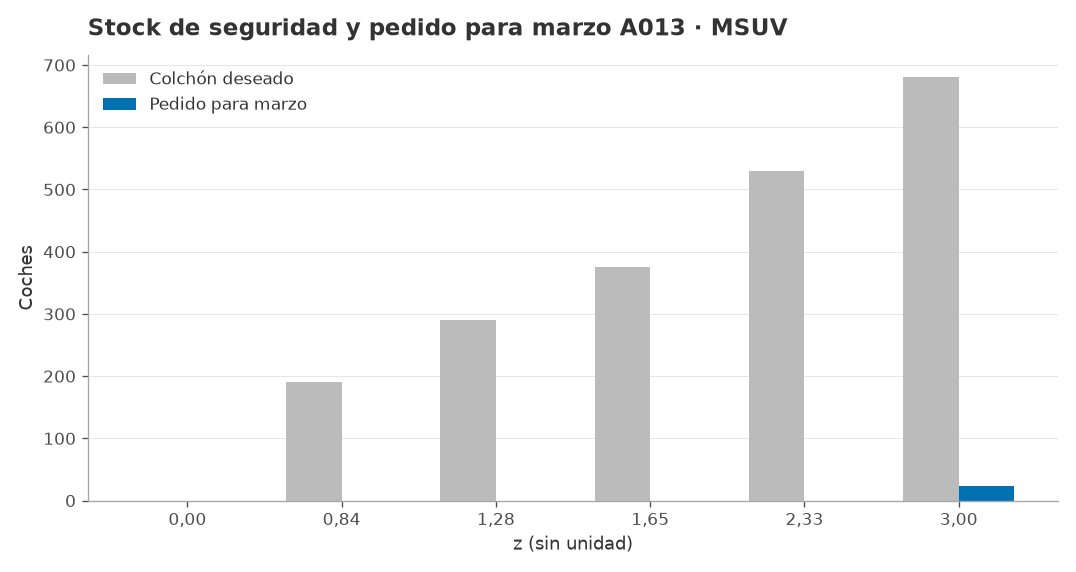

*Fuente: errores A009–A011, demanda prevista A013 y stock proyectado; fórmula del plan inicial.*

El colchón no es el pedido: primero se descuenta el stock que se espera conservar. z no garantiza por sí solo un porcentaje de servicio: lo medimos después con simulaciones.

In [24]:
z_malla = np.array([0, .84, 1.28, 1.65, 2.33, 3.0])
colchones = z_malla * sigma3[j] * demanda_plazo
pedidos = np.ceil(np.maximum(0, demanda_plan[2, j] + colchones - stock_proyectado))
fig, ax = plt.subplots()
posicion = np.arange(len(z_malla))
ax.bar(posicion - .18, colchones, .36, color="#BBBBBB", label="Colchón deseado")
ax.bar(posicion + .18, pedidos, .36, color=AZUL, label="Pedido para marzo")
ax.set_xticks(posicion, [numero(z, 2) for z in z_malla])
ax.set(title=f"Stock de seguridad y pedido para marzo A013 · {SEGMENTO_EJEMPLO}", xlabel="z (sin unidad)", ylabel="Coches")
ax.legend()
figura(fig, "07_colchon", "errores A009–A011, demanda prevista A013 y stock proyectado; fórmula del plan inicial.",
       "El colchón no es el pedido: primero se descuenta el stock que se espera conservar. "
       "z no garantiza por sí solo un porcentaje de servicio: lo medimos después con simulaciones.")

### 3.4. Revisión mensual y ejecución del plan

El plan inicial emplea solo la información disponible al cierre A012. Tras
terminar cada mes, el simulador revisa la llegada situada tres meses después;
no modifica retroactivamente las llegadas próximas.

La revisión utiliza el cociente $r=\sum V/\sum\widehat D$ de los últimos tres
meses disponibles. Durante enero y febrero solo hay uno o dos meses observados.
El multiplicador de revisión es

$$a=\max(0,1+0{,}5(r-1)).$$

Así se incorpora la mitad de la desviación observada. Por ejemplo, un cociente
$r=1{,}10$ da $a=1{,}05$. Si en alguno de esos meses se agotaron las unidades
disponibles, las ventas pueden estar limitadas por el stock: en ese caso se
sustituye $r$ por $\max(1,r)$ antes de calcular $a$. Esto evita reducir la previsión
solo porque no había coches que vender. El simulador no usa la demanda perdida
como si la empresa pudiera observarla.

Se multiplican por $a$ las previsiones relevantes, se vuelve a proyectar el stock
y se aplica la regla del pedido anterior. A continuación ejecutamos las reglas
durante A013, suponiendo de momento que la demanda coincide con la previsión
central redondeada. Esta es una **simulación determinista**: no contiene sorteos.

In [25]:
determinista = api_sim.simular_politica(
    np.rint(demanda_plan[:18])[None].astype(int), demanda_plan, datos, sigma3,
    z=Z_EJEMPLO, plan_inicial=plan)
mensual = determinista["mensual"]
balance = pd.DataFrame({nombre: mensual[nombre][0, :12, j] for nombre in
                       ["stock_inicial", "llegadas", "demanda", "ventas", "perdidas", "stock_fin"]}, index=MESES)
balance.insert(2, "disponibles", balance.stock_inicial + balance.llegadas)
tabla(balance, f"Balance mensual determinista · {SEGMENTO_EJEMPLO}, A013 · coches", 0)
assert np.allclose(balance.stock_fin, balance.disponibles - balance.ventas)
assert np.allclose(balance.demanda, balance.ventas + balance.perdidas)

Balance mensual determinista · MSUV, A013 · coches


,stock_inicial,llegadas,disponibles,demanda,ventas,perdidas,stock_fin
ene,536,576,1.112,254,254,0,858
feb,858,576,1.434,307,307,0,1.127
mar,1.127,0,1.127,468,468,0,659
abr,659,247,906,535,535,0,371
may,371,604,975,537,537,0,438
jun,438,678,1.116,633,633,0,483
jul,483,590,1.073,578,578,0,495
ago,495,307,802,358,358,0,444
sep,444,354,798,416,416,0,382
oct,382,459,841,485,485,0,356


In [26]:
# Revisión real del simulador al terminar enero: solo cambia la llegada de abril.
ventas_enero = mensual["ventas"][0, 0, j]
ratio = ventas_enero / demanda_plan[0, j] if demanda_plan[0, j] > 0 else ventas_enero
censurado = mensual["ventas_red"][0, 0, j] == balance.disponibles.iloc[0]
ratio_usado = max(1, ratio) if censurado else ratio
factor_revision = max(0, 1 + .5 * (ratio_usado - 1))
stock_abril = mensual["stock_fin"][0, 0, j]
for m in [1, 2]:
    stock_abril = max(0, stock_abril + plan[m, j] - demanda_plan[m, j] * factor_revision)
ss_abril = Z_EJEMPLO * sigma3[j] * demanda_plan[1:4, j].sum() * factor_revision
pedido_abril = int(np.ceil(max(0, demanda_plan[3, j] * factor_revision + ss_abril - stock_abril)))
assert pedido_abril == determinista["pedidos"][0, 0, j]
tabla(pd.DataFrame({"Llegada": ["ene A013", "feb A013", "mar A013", "abr A013"],
                    "Decisión": ["oct A012 (estimada)", "nov A012 (estimada)", "dic A012", "ene A013"],
                    "Plan inicial (coches)": plan[:4, j],
                    "Tras enero (coches)": [plan[0,j], plan[1,j], plan[2,j], pedido_abril]}),
      f"Tres meses entre decisión y llegada · {SEGMENTO_EJEMPLO}", 0)
print(f"Ventas/previsto de enero = {numero(ratio, 4)}; venta limitada por disponibilidad: {censurado}. "
      f"Factor de revisión = {numero(factor_revision, 4)}.")
print("La revisión pesa un 50 % y después usa hasta tres meses observados. Si se agotó el stock, "
      "no interpreta las ventas bajas como una caída segura de demanda; tampoco observa la demanda perdida real.")

Tres meses entre decisión y llegada · MSUV


,Llegada,Decisión,Plan inicial (coches),Tras enero (coches)
0,ene A013,oct A012 (estimada),576,576
1,feb A013,nov A012 (estimada),576,576
2,mar A013,dic A012,0,0
3,abr A013,ene A013,246,247


Ventas/previsto de enero = 1,0010; venta limitada por disponibilidad: False. Factor de revisión = 1,0005.
La revisión pesa un 50 % y después usa hasta tres meses observados. Si se agotó el stock, no interpreta las ventas bajas como una caída segura de demanda; tampoco observa la demanda perdida real.


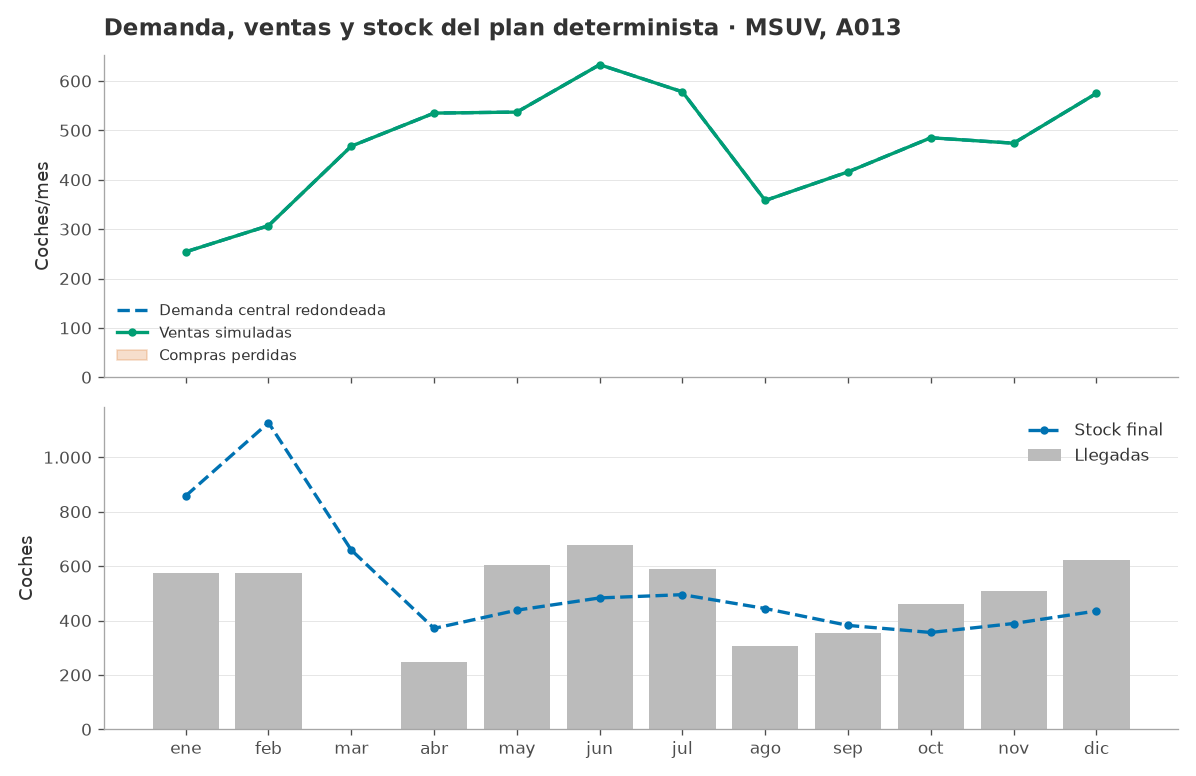

*Fuente: stock_red_mensual.csv y API simulacion.ipynb; A013 determinista.*

La demanda es una entrada; las ventas son una salida limitada por disponibilidad. Una llegada entra al principio del mes y la venta se aproxima en el día 15.

In [27]:
fig, ejes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ejes[0].plot(MESES, balance.demanda, color=AZUL, linestyle="--", label="Demanda central redondeada")
ejes[0].plot(MESES, balance.ventas, color=VERDE, marker="o", label="Ventas simuladas")
ejes[0].fill_between(np.arange(12), balance.ventas.to_numpy(), balance.demanda.to_numpy(), color=NARANJA, alpha=.2, label="Compras perdidas")
ejes[0].set(title=f"Demanda, ventas y stock del plan determinista · {SEGMENTO_EJEMPLO}, A013", ylabel="Coches/mes", ylim=(0, None))
ejes[0].legend(fontsize=9)
ejes[1].bar(MESES, balance.llegadas, color="#BBBBBB", label="Llegadas")
ejes[1].plot(MESES, balance.stock_fin, color=AZUL, linestyle="--", marker="o", label="Stock final")
ejes[1].set_ylabel("Coches")
ejes[1].legend()
figura(fig, "06_balance", "stock_red_mensual.csv y API simulacion.ipynb; A013 determinista.",
       "La demanda es una entrada; las ventas son una salida limitada por disponibilidad. "
       "Una llegada entra al principio del mes y la venta se aproxima en el día 15.")

## 4. Valoración del inventario y de las ventas

### 4.1. Antigüedad del stock y orden de venta

Dos coches del mismo segmento pueden producir distinta contribución económica
si tienen diferente antigüedad. Por eso el modelo no guarda únicamente el total
del stock: lo divide en **cohortes**, grupos de unidades con la misma edad
aproximada y las mismas condiciones de entrada.

Se aplica FIFO (*first in, first out*): primero se vende el grupo más antiguo.
Si $n_c$ son las unidades de la cohorte $c$, ordenada de más antigua a más nueva,
las ventas de esa cohorte son

$$v_c=\min\left(n_c,\max\left(0,D-\sum_{h<c}v_h\right)\right).$$

La expresión interior es la demanda todavía no atendida. Se repite hasta cubrir
la demanda o agotar el inventario. Las llegadas se reciben al principio del mes
y las ventas se sitúan, aproximadamente, en el día 15.

El stock inicial está observado por tramos: 0–90, 91–180 y más de 180 días.
Para operar con edades concretas, los dos primeros se reparten en tres grupos
y se representan por 15, 45, 75 y 105, 135, 165 días; al último se asignan 210 días.
Son aproximaciones a edades desconocidas dentro de cada tramo.

El **VM** (*Variable Marketing*) es el gasto comercial variable por coche vendido.
El catálogo da un importe distinto para cada tramo de edad. La tabla siguiente
aplica FIFO a las unidades reales de inicio y a la llegada estimada de enero.

In [28]:
cantidades = np.r_[api_sim._stock_inicial(datos)[:, j], plan[0, j]]
edades = np.r_[api_sim.EDADES_INICIALES, 0]
pendiente = int(mensual["demanda"][0, 0, j])
ventas_cohorte = []
for cantidad in cantidades:
    vendido = min(cantidad, pendiente)
    ventas_cohorte.append(vendido)
    pendiente -= vendido
venta_fifo = np.asarray(ventas_cohorte)
resto_fifo = cantidades - venta_fifo
tabla(pd.DataFrame({"Edad al inicio (días)": edades,
                    "Unidades disponibles": cantidades,
                    "Vendidas": venta_fifo, "Quedan": resto_fifo}),
      f"Venta por cohortes, de más antiguas a más nuevas · {SEGMENTO_EJEMPLO}, enero A013", 0)
assert venta_fifo.sum() == mensual["ventas_red"][0, 0, j]
explicar(
    f"Se venden {numero(venta_fifo.sum())} coches empezando por la cohorte más antigua. "
    "Una vez cubierta la demanda, las cohortes siguientes permanecen en stock. "
    "El balance total no basta para valorar estas ventas: necesitamos conocer "
    "de qué edades proceden, como muestra esta tabla.")

Venta por cohortes, de más antiguas a más nuevas · MSUV, enero A013


,Edad al inicio (días),Unidades disponibles,Vendidas,Quedan
0,210,35,35,0
1,165,22,22,0
2,135,22,22,0
3,105,22,22,0
4,75,145,145,0
5,45,145,8,137
6,15,145,0,145
7,0,576,0,576


Se venden 254 coches empezando por la cohorte más antigua. Una vez cubierta la demanda, las cohortes siguientes permanecen en stock. El balance total no basta para valorar estas ventas: necesitamos conocer de qué edades proceden, como muestra esta tabla.

### 4.2. Coste de almacenamiento y contribución por venta

La marca paga 2 € por coche y día, pero solo hasta que el coche cumple 180 días.
Para una cohorte de edad $a$ al inicio de un mes de $d$ días, una unidad vendida
el día 15 genera

$$c_{venta}(a)=2\max(0,\min(15,180-a)),$$

y una unidad que permanece todo el mes genera

$$c_{queda}(a)=2\max(0,\min(d,180-a)).$$

Por tanto, el coste de la cohorte es
$v_c\,c_{venta}(a_c)+(n_c-v_c)c_{queda}(a_c)$. Un coche de 175 días solo tiene
cinco días de coste adicional para la marca: $2\cdot5=10$ €. Un coche de más
de 180 días ya no genera este coste, aunque su venta puede requerir un VM mayor.
Los intereses del concesionario se calculan aparte y no se restan otra vez al
resultado de la marca.

Si $b_s$ es el beneficio bruto de una venta y $v_s(a)$ su VM por antigüedad,
la **contribución variable del producto**, o CVP, es

$$CVP_{unidad}=b_s-v_s(a).$$

Un *transfer* es una unidad externa que cubre directamente una compra que la
red no podía atender. Su coste es el 20 % del beneficio bruto, además del VM joven:
$CVP_{transfer}=b_s-v_s(\text{joven})-0{,}2b_s$. La política base no supone
disponibilidad garantizada de transfers.

In [29]:
bruto, vm_tramos, _, _ = api_sim._ficha(datos)

Catálogo · vender el mismo MSUV a distinta edad


,VM (€/coche),Bruto (€/coche),CVP (€/coche)
0–90 días,1.895,7.782,5.887
91–180 días,2.090,7.782,5.692
>180 días,2.422,7.782,5.360


Transfer joven: 7.782 − 1.895 − 20 % × 7.782 = 4.331 €/coche antes de otros recargos.
El 20 % se aplica al beneficio bruto, no al CVP. El VM >180 días de CSUV no está observado: el simulador usa el tramo 91–180 como supuesto.


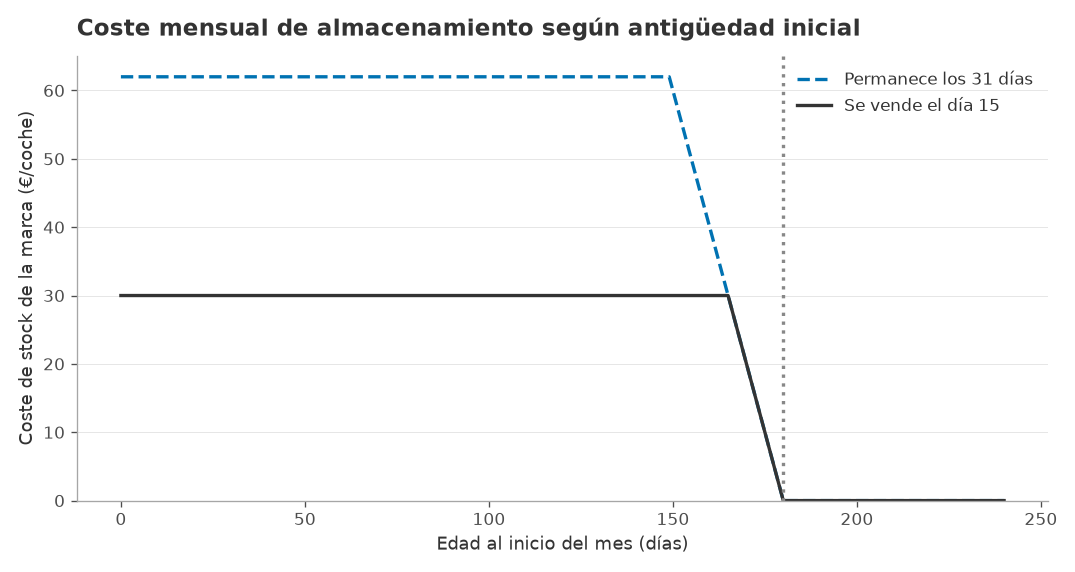

*Fuente: regla 2 €/coche/día del caso y convención de simulacion.ipynb; mes de 31 días.*

Un coche de 175 días solo genera 5 × 2 = 10 € adicionales para la marca. Que el almacenamiento deje de costar a la marca no evita el VM elevado de vender un coche viejo; los intereses del concesionario se separan.

In [30]:
ficha = datos["segmentos"].set_index("segmento").reindex(SEGMENTOS)
vm_joven, vm_medio, vm_viejo = vm_tramos[:, j]
tabla(pd.DataFrame({"VM (€/coche)": [vm_joven, vm_medio, vm_viejo],
                    "Bruto (€/coche)": bruto[j],
                    "CVP (€/coche)": bruto[j] - vm_tramos[:, j]}, index=["0–90 días", "91–180 días", ">180 días"]),
      f"Catálogo · vender el mismo {SEGMENTO_EJEMPLO} a distinta edad", 0)
print(f"Transfer joven: {numero(bruto[j])} − {numero(vm_joven)} − 20 % × {numero(bruto[j])} "
      f"= {numero(bruto[j] - vm_joven - .2*bruto[j])} €/coche antes de otros recargos.")
print("El 20 % se aplica al beneficio bruto, no al CVP. El VM >180 días de CSUV no está observado: "
      "el simulador usa el tramo 91–180 como supuesto.")

edades_prueba = np.arange(0, 241)
coste_vendido = 2 * np.clip(180 - edades_prueba, 0, 15)
coste_no_vendido = 2 * np.clip(180 - edades_prueba, 0, 31)
fig, ax = plt.subplots()
ax.plot(edades_prueba, coste_no_vendido, color=AZUL, linestyle="--", label="Permanece los 31 días")
ax.plot(edades_prueba, coste_vendido, color=GRIS, label="Se vende el día 15")
ax.axvline(180, color="#888888", linestyle=":")
ax.set(title="Coste mensual de almacenamiento según antigüedad inicial", xlabel="Edad al inicio del mes (días)", ylabel="Coste de stock de la marca (€/coche)", ylim=(0, None))
ax.legend()
figura(fig, "10_coste_edad", "regla 2 €/coche/día del caso y convención de simulacion.ipynb; mes de 31 días.",
       "Un coche de 175 días solo genera 5 × 2 = 10 € adicionales para la marca. "
       "Que el almacenamiento deje de costar a la marca no evita el VM elevado de vender un coche viejo; los intereses del concesionario se separan.")

In [31]:
tramos = np.where(edades + 15 <= 90, 0, np.where(edades + 15 <= 180, 1, 2))
dias_vendidos = np.clip(180 - edades, 0, 15)
dias_restantes = np.clip(180 - edades, 0, 31)
coste_cohorte = 2 * (venta_fifo * dias_vendidos + resto_fifo * dias_restantes)
vm_cohorte = venta_fifo * vm_tramos[tramos, j]
tabla(pd.DataFrame({"Edad al inicio (días)": edades, "Vendidas": venta_fifo,
                    "Quedan": resto_fifo, "Días facturados por vendida": dias_vendidos,
                    "Días facturados por no vendida": dias_restantes,
                    "Coste stock cohorte (€)": coste_cohorte, "VM cohorte (€)": vm_cohorte}),
      f"Valoración de las cohortes de enero A013 · {SEGMENTO_EJEMPLO}", 0)
assert np.isclose(vm_cohorte.sum(), mensual["vm"][0, 0, j])
assert np.isclose(coste_cohorte.sum(), mensual["coste_stock"][0, 0, j])
explicar(
    f"Las cohortes generan **{numero(coste_cohorte.sum())} € de almacenamiento** "
    f"y **{numero(vm_cohorte.sum())} € de VM** en enero. El primer importe incluye "
    "unidades vendidas y unidades que permanecen; el segundo corresponde únicamente "
    "a unidades vendidas. Son dos conceptos diferentes y ambos entran en la cuenta mensual.")

Valoración de las cohortes de enero A013 · MSUV


,Edad al inicio (días),Vendidas,Quedan,Días facturados por vendida,Días facturados por no vendida,Coste stock cohorte (€),VM cohorte (€)
0,210,35,0,0,0,0,84.770
1,165,22,0,15,15,660,45.980
2,135,22,0,15,31,660,45.980
3,105,22,0,15,31,660,45.980
4,75,145,0,15,31,4.350,274.775
5,45,8,137,15,31,8.734,15.160
6,15,0,145,15,31,8.990,0
7,0,0,576,15,31,35.712,0


Las cohortes generan **59.766 € de almacenamiento** y **512.645 € de VM** en enero. El primer importe incluye unidades vendidas y unidades que permanecen; el segundo corresponde únicamente a unidades vendidas. Son dos conceptos diferentes y ambos entran en la cuenta mensual.

### 4.3. Cuenta económica mensual

Para un mes, se suman las aportaciones de los coches efectivamente vendidos:

$$B=\sum_s b_sV_s,\qquad VM=\sum_{s,c}v_s(a_c)v_{s,c},\qquad CVP=B-VM.$$

El resultado tras costes modelizados es

$$R=CVP-C_{stock}-C_{transfer}-C_{CO_2}-C_{arancel}-C_{cambio}.$$

Cada término está en euros. Los recargos de arancel y cambio corresponden a nuevas
importaciones y se llevan al resultado cuando se vende la cohorte afectada;
no se asignan al stock inicial. Un coste de cambio negativo representa un ahorro.
La prima de CO₂, cuando se activa, se aplica por venta según el catálogo.

**Aplicación.** La cuenta de enero utiliza exactamente las ventas FIFO calculadas
antes. No se resta el VM dos veces: ya está incluido en la definición de CVP.
Tampoco se restan las compras perdidas como un gasto adicional, puesto que su
beneficio ya está ausente al calcular los ingresos solo sobre ventas realizadas.

In [32]:
conceptos = ["beneficio_bruto", "vm", "cvp", "coste_stock", "coste_transfer",
             "coste_co2", "coste_arancel", "coste_cambio", "resultado"]
cuenta_enero = pd.DataFrame({"Euros": [mensual[c][0, 0, j] for c in conceptos]}, index=conceptos)
tabla(cuenta_enero, f"{SEGMENTO_EJEMPLO} · enero A013 determinista: la cuenta de las ventas FIFO", 2)
costes = ["coste_stock", "coste_transfer", "coste_co2", "coste_arancel", "coste_cambio"]
resultado_manual = cuenta_enero.loc["cvp", "Euros"] - cuenta_enero.loc[costes, "Euros"].sum()
assert np.isclose(resultado_manual, cuenta_enero.loc["resultado", "Euros"])
print("El VM se resta una vez. Las ventas perdidas no se vuelven a restar como gasto: "
      "su margen ya falta porque beneficio bruto y VM se calculan solo sobre coches vendidos.")
print("Resultado significa contribución tras los costes modelizados, no beneficio neto contable: "
      "no se han añadido costes fijos ajenos al caso.")

MSUV · enero A013 determinista: la cuenta de las ventas FIFO


,Euros
beneficio_bruto,"1.976.628,00"
vm,"512.645,00"
cvp,"1.463.983,00"
coste_stock,"59.766,00"
coste_transfer,"0,00"
coste_co2,"0,00"
coste_arancel,"0,00"
coste_cambio,"0,00"
resultado,"1.404.217,00"


El VM se resta una vez. Las ventas perdidas no se vuelven a restar como gasto: su margen ya falta porque beneficio bruto y VM se calculan solo sobre coches vendidos.
Resultado significa contribución tras los costes modelizados, no beneficio neto contable: no se han añadido costes fijos ajenos al caso.


In [33]:
display(Math(
    rf"R_{{\mathrm{{ene}}}}={nlatex(cuenta_enero.loc['beneficio_bruto','Euros'], 2)}"
    rf"-{nlatex(cuenta_enero.loc['vm','Euros'], 2)}"
    rf"-{nlatex(cuenta_enero.loc['coste_stock','Euros'], 2)}"
    rf"={nlatex(resultado_manual, 2)}\;\text{{€}}."))
explicar(
    "En este ejemplo central los demás recargos son cero. La cuenta muestra por qué "
    "aumentar el inventario puede afectar a la rentabilidad incluso si se venden "
    "las mismas unidades: se acumulan días de almacenamiento y puede cambiar el VM "
    "de las cohortes vendidas. El resultado es contribución tras los costes incluidos "
    "en el modelo, no beneficio neto contable con todos los costes fijos de la empresa.")

<IPython.core.display.Math object>

En este ejemplo central los demás recargos son cero. La cuenta muestra por qué aumentar el inventario puede afectar a la rentabilidad incluso si se venden las mismas unidades: se acumulan días de almacenamiento y puede cambiar el VM de las cohortes vendidas. El resultado es contribución tras los costes incluidos en el modelo, no beneficio neto contable con todos los costes fijos de la empresa.

## 5. Simulación de una demanda incierta

### 5.1. Variable aleatoria y factor multiplicativo

Hasta ahora hemos usado una única demanda. Para estudiar los errores posibles,
consideramos $D_t$ una **variable aleatoria**: su valor puede cambiar de un futuro
simulado a otro. Una réplica es una secuencia completa de valores mensuales.

Representamos la demanda mediante un factor positivo $F_t$:

$$D_t=\operatorname{redondeo}(\widehat D_tF_t).$$

Si $F_t=1$, la demanda coincide con la previsión antes del redondeo; si $F_t=1{,}1$,
es un 10 % mayor. Usamos una distribución **lognormal**, lo que significa que
el logaritmo del factor sigue una distribución normal. En concreto,

$$Z\sim N(0,1),\qquad
F=\exp\left(\sigma_{log}Z-\frac{\sigma_{log}^2}{2}\right).$$

$N(0,1)$ es la normal de media cero y varianza uno. $\sigma_{log}$ controla la
dispersión del factor. Se estima con los errores mensuales
$\log[(C_t+0{,}5)/(\widehat D_t+0{,}5)]$ de la validación; la suma de 0,5 permite
tratar meses con cero compras. No es la misma dispersión relativa a tres meses
que utilizamos para el stock de seguridad.

La **esperanza** $E[F]$ es la media teórica bajo esa distribución. Como para una
normal estándar $E[e^{aZ}]=e^{a^2/2}$, resulta

$$E[F]=e^{-\sigma_{log}^2/2}E[e^{\sigma_{log}Z}]=1.$$

Sin la resta de $\sigma_{log}^2/2$, la generación elevaría sistemáticamente la
demanda media. La mediana del factor es $e^{-\sigma_{log}^2/2}$, menor que uno:
la distribución no es simétrica. La media de 1.000 sorteos solo aproxima la
esperanza; el redondeo a coches enteros puede modificar ligeramente esa media.

In [34]:
sd_log = base["sd_log"].reindex(SEGMENTOS).to_numpy()
valores_z = np.array([-1., 0., 1.])
factores_ejemplo = np.exp(sd_log[j] * valores_z - sd_log[j]**2 / 2)
tabla(pd.DataFrame({"Z (valor ilustrativo)": valores_z,
                    "Factor F": factores_ejemplo,
                    "Demanda de junio sin redondear (coches)": demanda_12[5,j] * factores_ejemplo,
                    "Demanda redondeada (coches)": np.rint(demanda_12[5,j] * factores_ejemplo)}),
      f"Aplicación de la transformación lognormal · {SEGMENTO_EJEMPLO}, junio A013", 3)
explicar(
    f"Con σ log = {numero(sd_log[j], 4)}, el factor para Z = 0 es "
    f"{numero(factores_ejemplo[1], 4)}, no uno. Estos tres valores de Z ilustran "
    "la transformación; no son tres escenarios equiprobables. La escala de demanda "
    "sí procede de la previsión real del proyecto.")

Aplicación de la transformación lognormal · MSUV, junio A013


,Z (valor ilustrativo),Factor F,Demanda de junio sin redondear (coches),Demanda redondeada (coches)
0,"-1,000","0,744","471,117","471,000"
1,"0,000","0,966","611,923","612,000"
2,"1,000","1,255","794,814","795,000"


Con σ log = 0,2615, el factor para Z = 0 es 0,9664, no uno. Estos tres valores de Z ilustran la transformación; no son tres escenarios equiprobables. La escala de demanda sí procede de la previsión real del proyecto.

### 5.2. Dependencia entre meses y segmentos

Sortear cada mes y cada segmento por separado supondría que sus desviaciones
son independientes. El modelo permite que un mes alto tienda a ir seguido de
otro alto, y que varios segmentos se desvíen a la vez.

La dependencia temporal se introduce con un proceso

$$U_t=\phi U_{t-1}+\sqrt{1-\phi^2}\,\varepsilon_t,$$

donde $U_1$ y las innovaciones $\varepsilon_t$ son normales estándar independientes.
Si $U_{t-1}$ tiene varianza uno, la nueva varianza es
$\phi^2+(1-\phi^2)=1$. Su correlación con el mes anterior es $\phi$.

Se genera un proceso común $U_t$ y otro propio $W_{t,s}$ para cada segmento,
independientes entre sí. El valor normal utilizado en el factor es

$$Z_{t,s}=\sqrt{\rho}\,U_t+\sqrt{1-\rho}\,W_{t,s}.$$

También conserva varianza uno. Dos segmentos comparten $U_t$ y tienen correlación
$\rho$ en estos valores normales; la correlación de sus demandas transformadas
no tiene por qué ser exactamente $\rho$. Los parámetros se estiman con errores
de validación; $\phi$ se acota entre −0,8 y 0,8 y $\rho$ entre 0 y 0,8.

**Aplicación.** Generamos 1.000 réplicas con semilla 42. Cada réplica contiene
18 meses y siete segmentos; los doce primeros meses forman A013 y los seis
siguientes permiten observar la continuación de los pedidos finales.

In [35]:
# Mismo orden de sorteos y semilla que escenarios.ipynb.
rng = np.random.default_rng(SEMILLA)
phi, rho = base["phi"], base["rho"]
sd_log = base["sd_log"].reindex(SEGMENTOS).to_numpy()
ruidos = []
for dimensiones in [1, len(SEGMENTOS)]:
    valores = np.empty((N_REPLICAS, 18, dimensiones))
    valores[:, 0] = rng.standard_normal((N_REPLICAS, dimensiones))
    for mes in range(1, 18):
        valores[:, mes] = (phi * valores[:, mes - 1]
                          + np.sqrt(1 - phi**2) * rng.standard_normal((N_REPLICAS, dimensiones)))
    ruidos.append(valores)
ruido = np.sqrt(rho) * ruidos[0] + np.sqrt(1 - rho) * ruidos[1]
factores = np.exp(ruido * sd_log[None, None, :] - sd_log[None, None, :]**2 / 2)
replicas_central = np.rint(demanda_plan[None, :18] * factores).astype(int)
tabla(pd.DataFrame({"Sigma relativa 3 meses": sigma3, "Sigma log mensual": sd_log}, index=SEGMENTOS),
      "Dos dispersiones distintas: pedidos y generación de demanda", 4)
print(f"Dependencia temporal φ = {numero(phi, 3)}; componente común ρ = {numero(rho, 3)}.")
print("φ y ρ se estiman con errores fuera de muestra y se acotan. "
      "Los segmentos comparten parte del ruido: sumar sus riesgos como si fueran independientes sería incorrecto.")

Dos dispersiones distintas: pedidos y generación de demanda


,Sigma relativa 3 meses,Sigma log mensual
B,"0,4286","0,3932"
C,"0,1379","0,2441"
MD,"0,1214","0,2413"
SSUV,"0,4433","0,3650"
CSUV,"0,4981","0,4698"
MSUV,"0,2209","0,2615"
S,"3,6843","1,0421"


Dependencia temporal φ = 0,210; componente común ρ = 0,190.
φ y ρ se estiman con errores fuera de muestra y se acotan. Los segmentos comparten parte del ruido: sumar sus riesgos como si fueran independientes sería incorrecto.


### 5.3. Media, mediana y percentiles de las réplicas

Para resumir los $N$ valores simulados de una cantidad $X$ usamos su media
$\bar X=\sum_rX^{(r)}/N$ y su mediana, que divide los valores ordenados en dos
mitades. El percentil 10, P10, deja aproximadamente el 10 % de los valores por
debajo; P90 deja aproximadamente el 90 % por debajo. Entre P10 y P90 queda el
80 % central de los valores.

La siguiente figura muestra, primero, frecuencias del factor: cada barra cuenta
cuántas réplicas caen en un intervalo. Después muestra la mediana y los percentiles
de la demanda en cada mes. Las cinco líneas finas son cinco réplicas concretas.
Una banda calculada por mes no significa que el 80 % de los años completos
permanezca dentro de ella todos los meses.

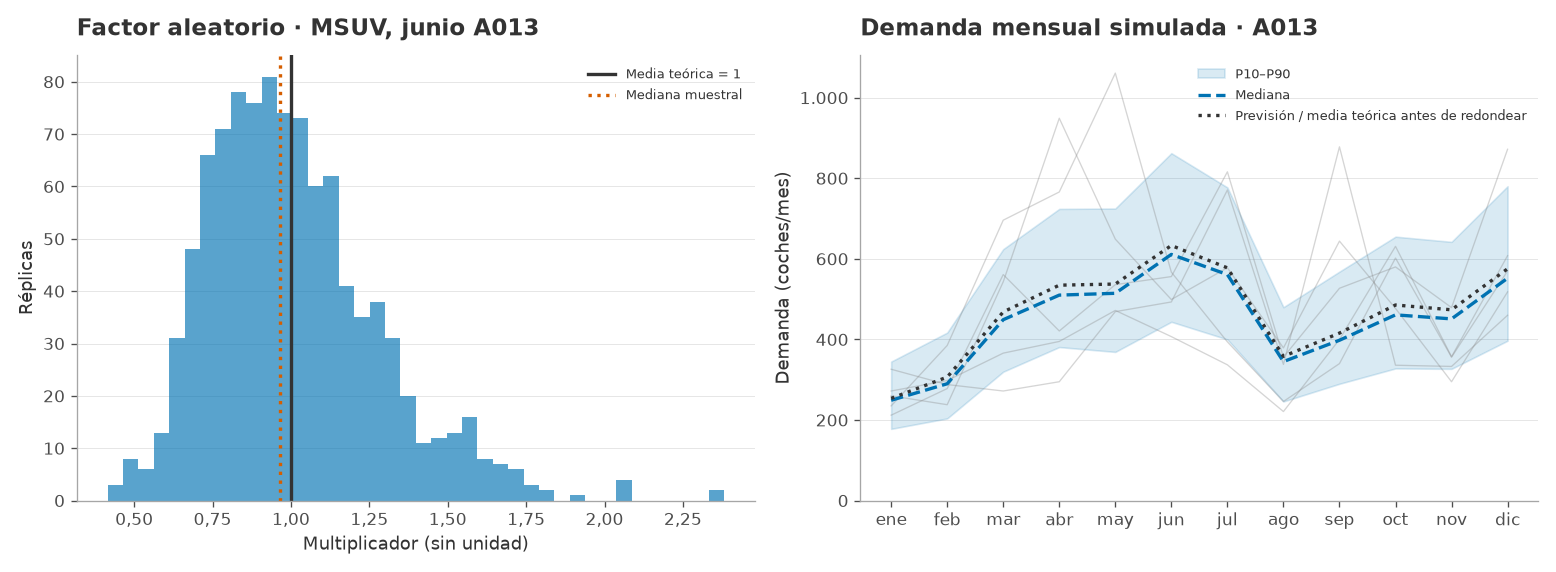

*Fuente: calibración A009–A011 y previsión central A013; lognormal, semilla 42.*

Media del factor de junio en esta muestra: 1,008. El rango P10–P90 contiene el 80 % central de las réplicas de cada mes, no el 80 % de las trayectorias completas.

In [36]:
factor_mes = factores[:, 5, j]
demanda_mensual = replicas_central[:, :12, j]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
ejes[0].hist(factor_mes, bins=40, color=AZUL, alpha=.65)
ejes[0].axvline(1, color=GRIS, label="Media teórica = 1")
ejes[0].axvline(np.median(factor_mes), color=NARANJA, linestyle=":", label="Mediana muestral")
ejes[0].set(title=f"Factor aleatorio · {SEGMENTO_EJEMPLO}, junio A013", xlabel="Multiplicador (sin unidad)", ylabel="Réplicas")
ejes[0].legend(fontsize=8)
for r in range(5):
    ejes[1].plot(MESES, demanda_mensual[r], color="#888888", alpha=.35, lw=.8)
ejes[1].fill_between(np.arange(12), *np.quantile(demanda_mensual, [.1, .9], axis=0), color=AZUL, alpha=.15, label="P10–P90")
ejes[1].plot(MESES, np.median(demanda_mensual, axis=0), color=AZUL, linestyle="--", label="Mediana")
ejes[1].plot(MESES, demanda_plan[:12, j], color=GRIS, linestyle=":", label="Previsión / media teórica antes de redondear")
ejes[1].set(title="Demanda mensual simulada · A013", ylabel="Demanda (coches/mes)", ylim=(0, None))
ejes[1].legend(fontsize=8)
figura(fig, "08_incertidumbre", "calibración A009–A011 y previsión central A013; lognormal, semilla 42.",
       f"Media del factor de junio en esta muestra: {numero(factor_mes.mean(), 3)}. "
       "El rango P10–P90 contiene el 80 % central de las réplicas de cada mes, no el 80 % de las trayectorias completas.")

Cada demanda simulada se introduce ahora en las mismas reglas de inventario,
pedidos y costes. La empresa revisa con las ventas de esa réplica; no conoce
sus demandas futuras. Así obtenemos ventas y resultado económico distintos
para cada futuro, manteniendo fijo el parámetro $z$ que se está evaluando.

El **nivel de servicio anual** de una réplica es la proporción de coches
demandados que se han vendido:

$$\eta^{(r)}=\frac{\sum_{t=1}^{12}V_t^{(r)}}{\sum_{t=1}^{12}D_t^{(r)}}.$$

No es la media aritmética de doce porcentajes mensuales: los meses con más demanda
deben pesar más. Para el total de Kaido se suman también los segmentos antes de
dividir. Análogamente, el resultado anual $R^{(r)}$ es la suma de los resultados
mensuales de esa réplica.

In [37]:
def ejecutar_politica(nombre, z, n=N_REPLICAS):
    demanda = np.rint(demandas_escenarios[nombre][None, :18] * factores[:n]).astype(int)
    plan_comun = api_sim.crear_plan(demanda_plan, datos, sigma3, z=z)
    return api_sim.simular_politica(demanda, demanda_plan, datos, sigma3, z=z,
                                  plan_inicial=plan_comun, parametros=parametros[nombre])

def resultados_anuales(salida):
    m = salida["mensual"]
    resultado = m["resultado"][:, :12].sum(axis=1)
    ventas = m["ventas"][:, :12].sum(axis=1)
    demanda = m["demanda"][:, :12].sum(axis=1)
    servicio = np.divide(ventas, demanda, out=np.ones_like(ventas), where=demanda > 0)
    stock = np.average(m["stock_medio"][:, :12], weights=api_sim.DIAS_MES, axis=1)
    return {"resultado": resultado, "servicio": servicio, "stock": stock}

bruto, vm_tramos, _, _ = api_sim._ficha(datos)
viable = bruto - vm_tramos[0] - 30 > 0
demandas_escenarios = {"central": demanda_plan}
parametros = {"central": {"frenar_no_rentables": True}}
salida_ejemplo = ejecutar_politica("central", Z_EJEMPLO)
resultado_ejemplo = resultados_anuales(salida_ejemplo)
replica = 0
demanda_anual = salida_ejemplo["mensual"]["demanda"][replica, :12, j].sum()
ventas_anuales = salida_ejemplo["mensual"]["ventas"][replica, :12, j].sum()
display(Math(
    rf"\eta^{{(1)}}_{{{SEGMENTO_EJEMPLO}}}="
    rf"\frac{{{nlatex(ventas_anuales)}}}{{{nlatex(demanda_anual)}}}"
    rf"={nlatex(100*ventas_anuales/demanda_anual, 2)}\,\%."))
tabla(pd.DataFrame({"Demanda anual (coches)": salida_ejemplo["mensual"]["demanda"][:5,:12,j].sum(axis=1),
                    "Ventas anuales (coches)": salida_ejemplo["mensual"]["ventas"][:5,:12,j].sum(axis=1),
                    "Servicio (%)": 100*resultado_ejemplo["servicio"][:5,j],
                    "Resultado (€)": resultado_ejemplo["resultado"][:5,j]}, index=np.arange(1,6)),
      f"Primeras cinco réplicas · {SEGMENTO_EJEMPLO}, A013, z = {numero(Z_EJEMPLO,2)}", 2)
explicar(
    "El stock inicial y el plan de partida son iguales, pero la demanda, las ventas "
    "y los pedidos revisados varían. Se desactivan nuevos pedidos cuando su contribución "
    "marginal estimada es negativa; en el central se evalúa como bruto menos VM joven "
    "menos 30 € de almacenamiento de una unidad vendida en 15 días. No se impide vender "
    "stock que ya existe.")

<IPython.core.display.Math object>

Primeras cinco réplicas · MSUV, A013, z = 1,28


,Demanda anual (coches),Ventas anuales (coches),Servicio (%),Resultado (€)
1,"4.764,00","4.764,00","100,00","27.205.208,00"
2,"5.259,00","4.778,00","90,85","27.301.379,00"
3,"6.029,00","5.755,00","95,46","33.263.504,00"
4,"6.194,00","6.131,00","98,98","35.460.318,00"
5,"6.218,00","5.777,00","92,91","33.323.197,00"


El stock inicial y el plan de partida son iguales, pero la demanda, las ventas y los pedidos revisados varían. Se desactivan nuevos pedidos cuando su contribución marginal estimada es negativa; en el central se evalúa como bruto menos VM joven menos 30 € de almacenamiento de una unidad vendida en 15 días. No se impide vender stock que ya existe.

## 6. Elección de la política y evaluación de escenarios

### 6.1. Maximización de la contribución con restricción de servicio

Una **política** fija el valor de $z$ que usarán los pedidos y sus revisiones.
Cada política produce una media de resultado $\bar R_s(z)$ y una media de servicio
$\bar\eta_s(z)$ en las réplicas. La regla de decisión busca, para cada segmento
viable, resolver sobre una malla finita

$$\max_{z\in\mathcal Z}\bar R_s(z)
\quad\text{sujeto a}\quad\bar\eta_s(z)\ge0{,}95,$$

$$\mathcal Z=\{0;\ 0{,}84;\ 1{,}28;\ 1{,}65;\ 2{,}33;\ 3\}.$$

El 95 % se exige a la **media de los servicios anuales**, no a todos los meses
ni a todas las réplicas. Una media suficiente puede coexistir con futuros de
servicio insuficiente. La viabilidad marginal se evalúa con la cuenta por
unidad descrita antes.

Primero se utilizan 200 réplicas piloto. Para comparar políticas se reutilizan
las mismas demandas: así una diferencia de resultado se debe a los pedidos y
no a haber sorteado una demanda más favorable para una de ellas.

In [38]:
pilotos, filas = {}, []
for z in z_malla:
    metricas = resultados_anuales(ejecutar_politica("central", z, N_PILOTO))
    pilotos[z] = metricas
    for k, segmento in enumerate(SEGMENTOS):
        filas.append({"segmento": segmento, "z": z,
                      "resultado_medio": metricas["resultado"][:, k].mean(),
                      "servicio_medio": metricas["servicio"][:, k].mean(),
                      "stock_medio": metricas["stock"][:, k].mean()})
busqueda = pd.DataFrame(filas)
ejemplo_politicas = busqueda.query("segmento == @SEGMENTO_EJEMPLO").set_index("z")
tabla(pd.DataFrame({"Contribución media (€)": ejemplo_politicas.resultado_medio,
                    "Servicio medio (%)": 100*ejemplo_politicas.servicio_medio,
                    "Stock medio (coches)": ejemplo_politicas.stock_medio,
                    "Cumple servicio medio ≥95 %": ejemplo_politicas.servicio_medio >= .95}),
      f"Comparación de seis políticas · {SEGMENTO_EJEMPLO}, A013 central · 200 réplicas", 2)

Comparación de seis políticas · MSUV, A013 central · 200 réplicas


,Contribución media (€),Servicio medio (%),Stock medio (coches),Cumple servicio medio ≥95 %
z,,,,
0.000000,"29.565.807,96","90,56","505,24",False
0.840000,"31.606.937,78","96,90","669,08",True
1.280000,"32.062.276,55","98,44","770,03",True
1.650000,"32.239.398,50","99,18","858,83",True
2.330000,"32.279.280,14","99,81","1.026,90",True
3.000000,"32.121.755,36","99,97","1.197,32",True


Las medias simuladas tienen error de muestreo: una ventaja pequeña puede no ser
concluyente con 200 réplicas. Para comparar el mejor resultado factible con otro
candidato calculamos, en cada réplica, la diferencia emparejada
$\Delta_r=R_r(z_{mejor})-R_r(z)$. Su error estándar se aproxima mediante

$$EE(\bar\Delta)=\frac{s_\Delta}{\sqrt{N}},$$

donde $s_\Delta$ es la desviación típica muestral de las diferencias y $N=200$.
Esto no es la dispersión de resultados de la empresa: mide la precisión con
la que la simulación estima la **diferencia media** entre dos políticas.

El proyecto considera elegibles los candidatos factibles cuya desventaja media
no supera dos errores estándar respecto al mejor. Entre ellos elige el menor $z$.
Es una regla práctica para no aumentar protección por una mejora apenas
distinguible del ruido de simulación, no una prueba de optimalidad global.

In [39]:
viable = (bruto - vm_tramos[0] - 30) > 0
z_recomendado = np.zeros(7)
criterios = []
for k, segmento in enumerate(SEGMENTOS):
    grupo = busqueda[busqueda.segmento.eq(segmento)]
    factibles = grupo[(grupo.servicio_medio >= .95) | ~viable[k]]
    if factibles.empty:
        factibles = grupo[grupo.servicio_medio >= grupo.servicio_medio.max() - 1e-12]
    mejor = factibles.loc[factibles.resultado_medio.idxmax(), "z"]
    elegibles = []
    for z in factibles.z:
        diferencia = pilotos[mejor]["resultado"][:, k] - pilotos[z]["resultado"][:, k]
        error_estandar = diferencia.std(ddof=1) / np.sqrt(N_PILOTO)
        if diferencia.mean() <= 2 * error_estandar + 1e-8:
            elegibles.append(z)
    z_recomendado[k] = min(elegibles)
    criterios.append("Menor z a ≤2 errores estándar del mejor factible")
z_piloto = z_recomendado.copy()
print("Entre políticas factibles, se busca más contribución. Si la ventaja frente a otra no supera "
      "dos errores estándar de la diferencia emparejada, se prefiere el menor z.")
print("Es una elección entre políticas probadas, no una optimización continua ni un z-score "
      "que garantice por fórmula el 95 % de servicio.")

Entre políticas factibles, se busca más contribución. Si la ventaja frente a otra no supera dos errores estándar de la diferencia emparejada, se prefiere el menor z.
Es una elección entre políticas probadas, no una optimización continua ni un z-score que garantice por fórmula el 95 % de servicio.


Aplicación de la regla de selección · MSUV; mejor media con z = 2,33


,Desventaja media (€),Dos errores estándar (€),Elegible
z,,,
0.840000,"672.342,35","166.095,21",False
1.280000,"217.003,58","105.015,85",False
1.650000,"39.881,64","60.397,12",True
2.330000,"0,00","0,00",True
3.000000,"157.524,77","34.637,80",False


La política piloto elige **z = 1,65** para MSUV. La comparación se hace entre candidatos que ya cumplen la restricción de servicio; una política más rentable que no la cumple no es admisible por ese solo motivo.

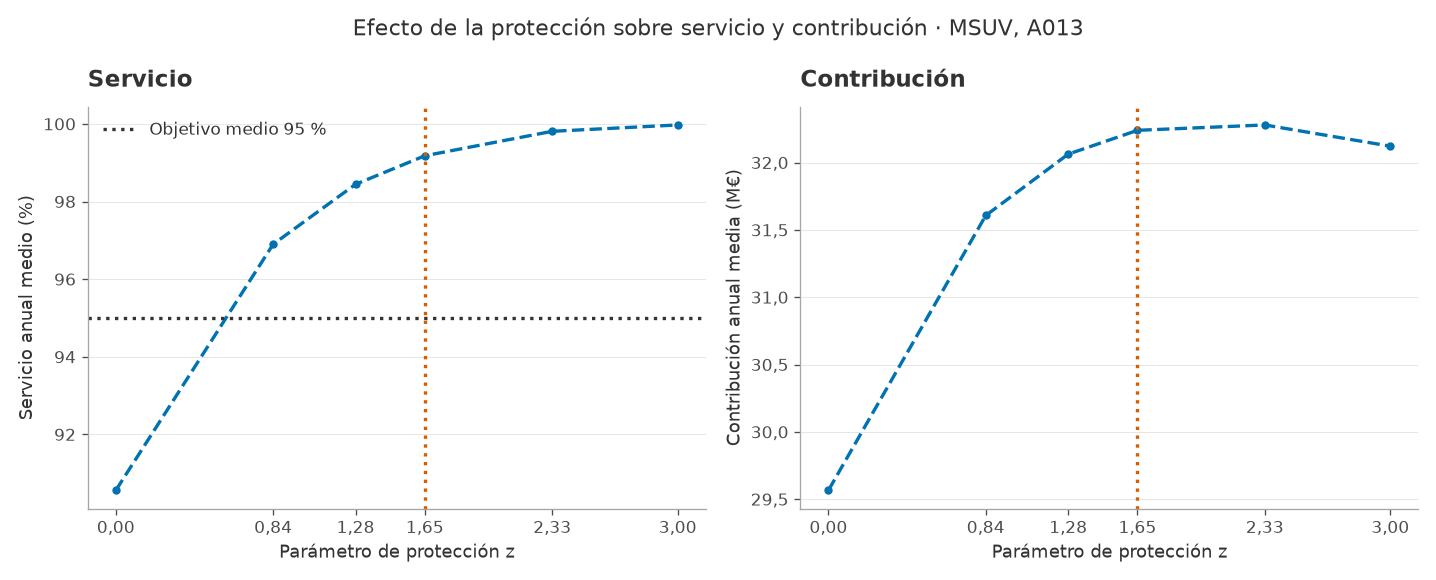

*Fuente: 200 réplicas centrales comunes por política; línea vertical = z elegido.*

Las escalas verticales son distintas porque se representan magnitudes distintas. El servicio puede aumentar mientras la contribución deja de mejorar: mantener más coches tiene costes de almacenamiento y antigüedad. La tabla anterior determina cuáles de las diferencias económicas son suficientemente grandes para la regla utilizada.

In [40]:
factibles_ejemplo = ejemplo_politicas[ejemplo_politicas.servicio_medio >= .95]
mejor_z = factibles_ejemplo.resultado_medio.idxmax()
comparaciones = []
for z in factibles_ejemplo.index:
    diferencias = pilotos[mejor_z]["resultado"][:,j] - pilotos[z]["resultado"][:,j]
    ee = diferencias.std(ddof=1) / np.sqrt(N_PILOTO)
    comparaciones.append({"z": z, "Desventaja media (€)": diferencias.mean(),
                           "Dos errores estándar (€)": 2*ee,
                           "Elegible": diferencias.mean() <= 2*ee + 1e-8})
tabla(pd.DataFrame(comparaciones).set_index("z"),
      f"Aplicación de la regla de selección · {SEGMENTO_EJEMPLO}; mejor media con z = {numero(mejor_z,2)}", 2)
explicar(
    f"La política piloto elige **z = {numero(z_piloto[j],2)}** para {SEGMENTO_EJEMPLO}. "
    "La comparación se hace entre candidatos que ya cumplen la restricción de servicio; "
    "una política más rentable que no la cumple no es admisible por ese solo motivo.")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
posiciones = z_malla
etiquetas = [numero(z,2) for z in z_malla]
ejes[0].plot(posiciones, 100*ejemplo_politicas.servicio_medio, color=AZUL, marker="o", linestyle="--")
ejes[0].axhline(95, color=GRIS, linestyle=":", label="Objetivo medio 95 %")
ejes[0].set(ylabel="Servicio anual medio (%)", title="Servicio")
ejes[0].legend()
ejes[1].plot(posiciones, ejemplo_politicas.resultado_medio/1e6, color=AZUL, marker="o", linestyle="--")
ejes[1].set(ylabel="Contribución anual media (M€)", title="Contribución")
for ax in ejes:
    ax.set_xticks(posiciones, etiquetas)
    ax.set_xlabel("Parámetro de protección z")
    ax.axvline(z_piloto[j], color=NARANJA, linestyle=":")
fig.suptitle(f"Efecto de la protección sobre servicio y contribución · {SEGMENTO_EJEMPLO}, A013")
figura(fig, "11_eleccion_politica", "200 réplicas centrales comunes por política; línea vertical = z elegido.",
       "Las escalas verticales son distintas porque se representan magnitudes distintas. "
       "El servicio puede aumentar mientras la contribución deja de mejorar: mantener más "
       "coches tiene costes de almacenamiento y antigüedad. La tabla anterior determina "
       "cuáles de las diferencias económicas son suficientemente grandes para la regla utilizada.")

### 6.2. Comprobación con 1.000 réplicas

Se combinan las decisiones de los siete segmentos y se calculan 1.000 réplicas
centrales. Si algún segmento viable no alcanza el 95 % medio, se prueban niveles
superiores, ampliando la malla hasta 4 y 6 si hace falta. La tabla informa del
valor final y del piloto para que cualquier cambio sea visible.

Además de la media se calcula el P10 del servicio y la proporción de réplicas
que no alcanzan el 95 %. Esta última se obtiene contando incumplimientos y
dividiendo por 1.000. Es una frecuencia bajo los supuestos del modelo, no una
garantía sobre el mundo real. Las primeras 200 réplicas pertenecen también al
conjunto final: la comprobación no constituye una muestra completamente independiente.

In [41]:
salida_central = ejecutar_politica("central", z_recomendado)
for k, segmento in enumerate(SEGMENTOS):
    servicio_actual = resultados_anuales(salida_central)["servicio"][:, k].mean()
    if viable[k] and servicio_actual < .95:
        for candidato in [z for z in list(z_malla) + [4., 6.] if z > z_recomendado[k]]:
            z_prueba = z_recomendado.copy()
            z_prueba[k] = candidato
            prueba = ejecutar_politica("central", z_prueba)
            servicio_prueba = resultados_anuales(prueba)["servicio"][:, k].mean()
            if servicio_prueba > servicio_actual + 1e-8:
                z_recomendado, salida_central = z_prueba, prueba
                servicio_actual = servicio_prueba
                criterios[k] = "Protección aumentada al verificar 1.000 réplicas"
            if servicio_actual >= .95:
                break
metricas_central = resultados_anuales(salida_central)
politica = pd.DataFrame({"z piloto": z_piloto, "z final": z_recomendado,
                        "Viable": viable,
                        "Servicio medio (%)": 100 * metricas_central["servicio"].mean(axis=0),
                        "P10 servicio (%)": 100 * np.quantile(metricas_central["servicio"], .1, axis=0),
                        "Réplicas por debajo del 95 % (%)": 100 * (metricas_central["servicio"] < .95).mean(axis=0)}, index=SEGMENTOS)
tabla(politica, "Política final · A013 central · 1.000 réplicas", 2)
print("La comprobación final comparte las primeras 200 réplicas del piloto: no es una validación "
      "independiente. El P10 y la frecuencia de incumplimiento muestran el riesgo que oculta la media.")

Política final · A013 central · 1.000 réplicas


,z piloto,z final,Viable,Servicio medio (%),P10 servicio (%),Réplicas por debajo del 95 % (%)
B,"0,84","0,84",True,"96,50","89,56","27,10"
C,"1,65","1,65",True,"99,62","98,67","1,90"
MD,"3,00","3,00",True,"99,65","98,99","1,70"
SSUV,"0,84","0,84",True,"95,36","89,27","39,10"
CSUV,"1,28","1,28",True,"98,34","93,11","13,00"
MSUV,"1,65","1,65",True,"99,22","97,13","5,00"
S,"0,84","0,84",True,"95,97","85,51","22,30"


La comprobación final comparte las primeras 200 réplicas del piloto: no es una validación independiente. El P10 y la frecuencia de incumplimiento muestran el riesgo que oculta la media.


### 6.3. Escenarios y comparación de resultados

Las réplicas anteriores variaban la demanda alrededor del escenario central.
Un **escenario** cambia los supuestos de ese centro o los costes: no es otra
réplica aleatoria del mismo centro. El proyecto considera pesimista, central
y optimista sin asignarles probabilidades.

La API de demanda modifica economía, turismo y producto mediante hipótesis
explícitas. Para la economía de los extremos se utiliza el cociente entre las
previsiones de un modelo auxiliar con paro, crédito y confianza, bajo el choque
y sin él. Ese cociente multiplica el nivel central; no sustituye el modelo central
seleccionado. El turismo modifica la demanda de marzo–junio según la relación
histórica con alquiler y el peso de ese canal. El producto central es neutro;
el optimista contrasta efectos de renovación durante seis meses. Estas relaciones
históricas no se interpretan como efectos causales identificados.

Se aplica además un cambio exploratorio de demanda por combustible: −3 %, 0 %
y +3 %. Después se descuenta la misma cantidad de adelanto, repartida entre seis,
tres o un mes respectivamente. El orden importa: el adelanto es una cantidad
absoluta que no debe multiplicarse otra vez por el choque de combustible.

En costes, el pesimista añade 500 €/nueva importación y la prima de CO₂ del catálogo;
también pierde la producción MSUV de marzo, cuya llegada habría sido en junio.
El optimista supone un ahorro de cambio de 250 €/nueva importación. Estos tamaños
son supuestos exploratorios. Los tres escenarios parten del mismo plan central
y revisan después con la información observada en cada réplica.

El mismo adelanto, distintos plazos A013


,Adelanto solicitado (coches),Aplicado (coches),No aplicado (coches)
Escenario,,,
pesimista,"878,4","878,4","-0,0"
central,"878,4","878,4","-0,0"
optimista,"878,4","643,1","235,3"


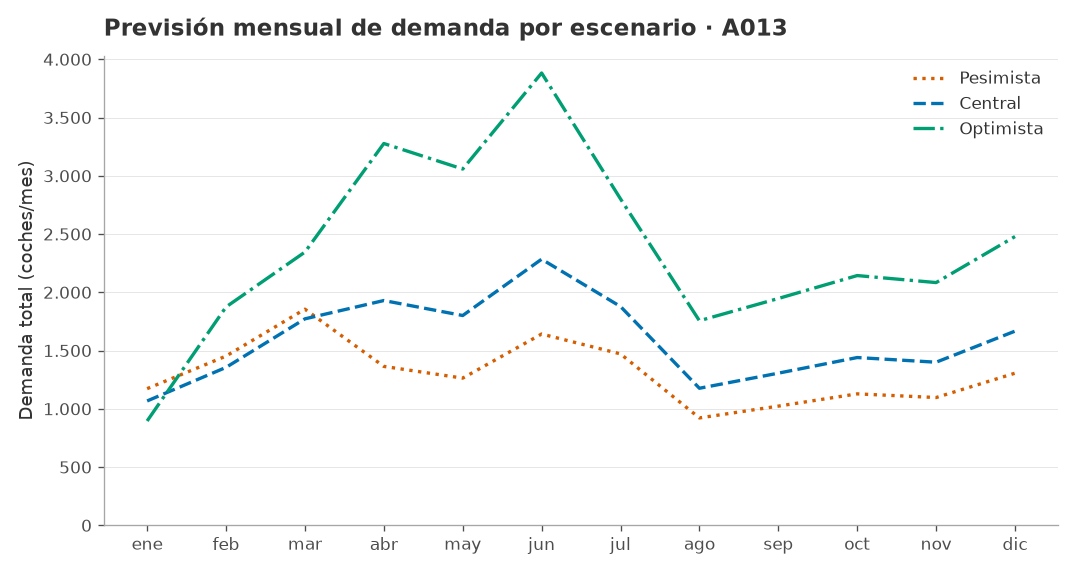

*Fuente: API de demanda y supuestos de escenarios.ipynb; combustible antes de descontar el ledger.*

Cada línea combina supuestos de economía, turismo, producto y adelantos. Las 1.000 réplicas describen variación dentro de cada escenario: no asignan probabilidad a estas tres líneas.

In [42]:
ESCENARIOS = ["pesimista", "central", "optimista"]
colores = {"pesimista": NARANJA, "central": AZUL, "optimista": VERDE}
trazos = {"pesimista": ":", "central": "--", "optimista": "-."}
combustible = {"pesimista": -.03, "central": 0, "optimista": .03}
duracion = {"pesimista": 6, "central": 3, "optimista": 1}
ledger = base["adelantos"].set_index("segmento").adelanto_central.reindex(SEGMENTOS).to_numpy()
demandas_escenarios, registros_ledger = {}, []
for nombre in ESCENARIOS:
    previa = api_demanda.prever_escenario_revision(base, nombre, {"sin_ledger": True}).to_numpy()
    previa = previa * (1 + combustible[nombre])
    neta = previa.copy()
    meses = duracion[nombre]
    neta[:meses] = np.maximum(0, neta[:meses] - ledger / meses)
    aplicado = (previa - neta).sum()
    registros_ledger.append({"Escenario": nombre, "Adelanto solicitado (coches)": ledger.sum(),
                             "Aplicado (coches)": aplicado, "No aplicado (coches)": ledger.sum() - aplicado})
    demandas_escenarios[nombre] = api_sim.extender_demanda(neta, datos, meses=21)
assert np.allclose(demandas_escenarios["central"], demanda_plan)
tabla(pd.DataFrame(registros_ledger).set_index("Escenario"), "El mismo adelanto, distintos plazos A013", 1)

fig, ax = plt.subplots()
for nombre in ESCENARIOS:
    ax.plot(MESES, demandas_escenarios[nombre][:12].sum(axis=1), color=colores[nombre],
            linestyle=trazos[nombre], label=nombre.capitalize())
ax.set(title="Previsión mensual de demanda por escenario · A013", ylabel="Demanda total (coches/mes)", ylim=(0, None))
ax.legend()
figura(fig, "09_escenarios", "API de demanda y supuestos de escenarios.ipynb; combustible antes de descontar el ledger.",
       "Cada línea combina supuestos de economía, turismo, producto y adelantos. "
       "Las 1.000 réplicas describen variación dentro de cada escenario: no asignan probabilidad a estas tres líneas.")

In [43]:
tabla(base["parametros_escenarios"].query("factor in ['paro', 'confianza_consumidor', 'tipo_credito_consumo', 'turismo', 'ayuda']")
      .pivot(index="factor", columns="escenario", values="valor").reindex(columns=ESCENARIOS),
      "Choques de demanda · puntos del indicador; ayuda es indicador abril–diciembre", 2)
tabla(pd.DataFrame({"Combustible: demanda (%)": [-3, 0, 3],
                    "Arancel nueva importación (€/coche)": [500, 0, 0],
                    "Cambio nueva importación (€/coche)": [0, 0, -250],
                    "Prima CO₂ del catálogo": ["Sí", "No", "No"],
                    "Producción MSUV marzo": ["Interrumpida: falta llegada junio", "Normal", "Normal"]}, index=ESCENARIOS),
      "Supuestos económicos y de suministro de la simulación", 0)
print("Combustible, arancel y cambio son tamaños exploratorios; no coeficientes causales estimados. "
      "El producto central es neutro: el contraste antes/después no identifica una mejora causal.")
print("A014 prolonga el nivel desestacionalizado de octubre–diciembre A013 con el perfil A009–A010. "
      "Sirve para seguir pedidos tardíos; no se inventa una venta del inventario final.")

Choques de demanda · puntos del indicador; ayuda es indicador abril–diciembre


escenario,pesimista,central,optimista
factor,,,
ayuda,"0,00","0,00","1,00"
confianza_consumidor,"-16,26","0,00","19,14"
paro,"2,00","0,00","-1,00"
tipo_credito_consumo,"0,55","0,00","-0,55"
turismo,"-8,20","0,00","9,67"


Supuestos económicos y de suministro de la simulación


,Combustible: demanda (%),Arancel nueva importación (€/coche),Cambio nueva importación (€/coche),Prima CO₂ del catálogo,Producción MSUV marzo
pesimista,-3,500,0,Sí,Interrumpida: falta llegada junio
central,0,0,0,No,Normal
optimista,3,0,-250,No,Normal


Combustible, arancel y cambio son tamaños exploratorios; no coeficientes causales estimados. El producto central es neutro: el contraste antes/después no identifica una mejora causal.
A014 prolonga el nivel desestacionalizado de octubre–diciembre A013 con el perfil A009–A010. Sirve para seguir pedidos tardíos; no se inventa una venta del inventario final.


In [44]:
parametros.update({
    "pesimista": {"prima_co2": True, "arancel_eur": np.full(7, 500.),
                   "suministro": ("MSUV", 3), "frenar_no_rentables": True},
    "optimista": {"cambio_eur": np.full(7, -250.), "frenar_no_rentables": True},
})

Para cada escenario sumamos meses y segmentos **dentro de cada réplica** y
después calculamos media, mediana, P10 y P90. No se suman percentiles individuales:
el décimo percentil de una suma no es, en general, la suma de los décimos percentiles.

En la figura siguiente cada segmento horizontal muestra P10–P90 del resultado
anual total; el punto marca la mediana y la cruz la media. La posición horizontal
permite comparar los importes en millones de euros. La tabla da los valores
numéricos y el servicio medio correspondiente.

Resultado del mismo plan inicial en tres escenarios · A013 · 1.000 réplicas


,Ventas medias (coches),Servicio medio (%),Resultado medio (M€),Mediana (M€),P10 (M€),P90 (M€)
Escenario,,,,,,
pesimista,"12.151,44","77,78","3,09","3,03","1,87","4,35"
central,"18.538,50","97,56","62,88","62,78","56,45","69,47"
optimista,"24.952,32","87,95","91,37","91,24","84,52","98,39"


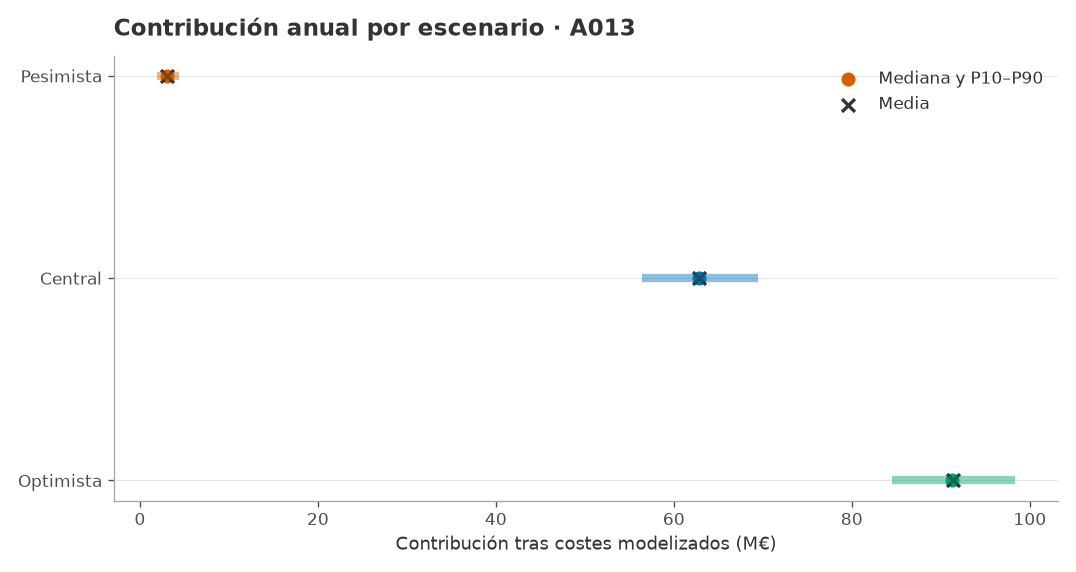

*Fuente: simulación de 1.000 réplicas por escenario; política revisada y parámetros mostrados arriba.*

Las medias resumen el valor esperado bajo cada supuesto; el rango muestra su variabilidad. No se promedian los tres escenarios entre sí porque no tienen probabilidades asignadas.

In [45]:
salidas = {nombre: salida_central if nombre == "central" else ejecutar_politica(nombre, z_recomendado)
           for nombre in ESCENARIOS}
resumen_filas, resultados_totales = [], {}
for nombre, salida in salidas.items():
    m = salida["mensual"]
    # Primero sumar segmentos y meses dentro de cada réplica; luego calcular percentiles.
    resultado_total = m["resultado"][:, :12].sum(axis=(1, 2))
    ventas_total = m["ventas"][:, :12].sum(axis=(1, 2))
    demanda_total = m["demanda"][:, :12].sum(axis=(1, 2))
    servicio_total = ventas_total / demanda_total
    resultados_totales[nombre] = resultado_total
    resumen_filas.append({"Escenario": nombre, "Ventas medias (coches)": ventas_total.mean(),
                          "Servicio medio (%)": 100 * servicio_total.mean(),
                          "Resultado medio (M€)": resultado_total.mean() / 1e6,
                          "Mediana (M€)": np.median(resultado_total) / 1e6,
                          "P10 (M€)": np.quantile(resultado_total, .1) / 1e6,
                          "P90 (M€)": np.quantile(resultado_total, .9) / 1e6})
resumen = pd.DataFrame(resumen_filas).set_index("Escenario")
tabla(resumen, "Resultado del mismo plan inicial en tres escenarios · A013 · 1.000 réplicas", 2)

fig, ax = plt.subplots()
for posicion, nombre in enumerate(ESCENARIOS):
    valores = resultados_totales[nombre] / 1e6
    p10, mediana, p90 = np.quantile(valores, [.1, .5, .9])
    ax.hlines(posicion, p10, p90, color=colores[nombre], lw=5, alpha=.45)
    ax.scatter(mediana, posicion, color=colores[nombre], marker="o", s=55,
               label="Mediana y P10–P90" if posicion == 0 else None)
    ax.scatter(valores.mean(), posicion, color=GRIS, marker="x", s=60,
               label="Media" if posicion == 0 else None)
ax.set_yticks(range(3), [n.capitalize() for n in ESCENARIOS])
ax.invert_yaxis()
ax.set(title="Contribución anual por escenario · A013", xlabel="Contribución tras costes modelizados (M€)")
ax.legend()
figura(fig, "12_resultados", "simulación de 1.000 réplicas por escenario; política revisada y parámetros mostrados arriba.",
       "Las medias resumen el valor esperado bajo cada supuesto; el rango muestra su variabilidad. "
       "No se promedian los tres escenarios entre sí porque no tienen probabilidades asignadas.")

In [46]:
cuentas = pd.DataFrame({nombre: {c: salida["mensual"][c][:, :12].sum(axis=(1, 2)).mean() / 1e6
                               for c in conceptos} for nombre, salida in salidas.items()})
tabla(cuentas, "De beneficio bruto a contribución · A013 · medias en M€", 3)
assert np.allclose(cuentas.loc["beneficio_bruto"] - cuentas.loc["vm"], cuentas.loc["cvp"])
assert np.allclose(cuentas.loc["cvp"] - cuentas.loc[costes].sum(), cuentas.loc["resultado"])
print("Arancel y cambio se asignan a las nuevas llegadas y se llevan a resultado al vender esas unidades. "
      "El stock inicial no recibe esos recargos; el coste de cambio negativo del optimista es un ahorro.")

co2_mismas_ventas = (salida_central["mensual"]["ventas"][:, :12]
                    * ficha.prima_co2_eur.to_numpy()).sum(axis=(1, 2))
print(f"Solo aplicar CO₂ a las MISMAS ventas centrales reduciría la contribución media en "
      f"{numero(co2_mismas_ventas.mean()/1e6, 2)} M€.")
print("Esta cuenta aísla el efecto contable; la diferencia central–pesimista incluye también "
      "demanda, suministro, pedidos y arancel. No se puede atribuir entera al CO₂.")

De beneficio bruto a contribución · A013 · medias en M€


,pesimista,central,optimista
beneficio_bruto,"74,129","106,111","141,593"
vm,"27,634","40,496","53,359"
cvp,"46,495","65,615","88,235"
coste_stock,"2,198","2,733","2,379"
coste_transfer,"0,000","0,000","0,000"
coste_co2,"36,565","0,000","0,000"
coste_arancel,"4,637","0,000","0,000"
coste_cambio,"0,000","0,000","-5,519"
resultado,"3,095","62,882","91,374"


Arancel y cambio se asignan a las nuevas llegadas y se llevan a resultado al vender esas unidades. El stock inicial no recibe esos recargos; el coste de cambio negativo del optimista es un ahorro.
Solo aplicar CO₂ a las MISMAS ventas centrales reduciría la contribución media en 55,01 M€.
Esta cuenta aísla el efecto contable; la diferencia central–pesimista incluye también demanda, suministro, pedidos y arancel. No se puede atribuir entera al CO₂.


In [47]:
explicar(
    f"Bajo los supuestos centrales, la política obtiene una contribución media de "
    f"**{numero(resumen.loc['central','Resultado medio (M€)'],2)} M€**, con P10–P90 entre "
    f"**{numero(resumen.loc['central','P10 (M€)'],2)} y {numero(resumen.loc['central','P90 (M€)'],2)} M€**. "
    f"En el pesimista la media es {numero(resumen.loc['pesimista','Resultado medio (M€)'],2)} M€ "
    f"y en el optimista {numero(resumen.loc['optimista','Resultado medio (M€)'],2)} M€. "
    "No existe una media conjunta justificada sin asignar probabilidades a los escenarios. "
    "La diferencia entre ellos incorpora simultáneamente cambios de demanda, costes "
    "y decisiones de reposición; no mide por sí sola el efecto aislado de una variable.")

Bajo los supuestos centrales, la política obtiene una contribución media de **62,88 M€**, con P10–P90 entre **56,45 y 69,47 M€**. En el pesimista la media es 3,09 M€ y en el optimista 91,37 M€. No existe una media conjunta justificada sin asignar probabilidades a los escenarios. La diferencia entre ellos incorpora simultáneamente cambios de demanda, costes y decisiones de reposición; no mide por sí sola el efecto aislado de una variable.

### 6.4. Pedidos pendientes y alcance de la conclusión

Un pedido de diciembre A013 llega en marzo A014. Si se cortara todo el cálculo
en diciembre, se omitirían parte de sus consecuencias. La continuación hasta
junio A014 permite observar ventas, costes y existencias posteriores bajo el
supuesto de demanda prolongada descrito en el apartado 3.3. El inventario final
no se convierte artificialmente en ingresos.

La conclusión económica está condicionada a los datos, la previsión, las reglas
de operación y los supuestos de los escenarios. La selección identifica una
política entre las examinadas, no la mejor política posible bajo cualquier
modelo de demanda.

In [48]:
continuidad = []
for nombre, salida in salidas.items():
    m = salida["mensual"]
    continuidad.append({"Escenario": nombre,
                         "Pedidos dic A013 → mar A014 (coches)": salida["pedidos"][:, 11].sum(axis=1).mean(),
                         "Stock dic A013 (coches)": m["stock_fin"][:, 11].sum(axis=1).mean(),
                         "Stock jun A014 (coches)": m["stock_fin"][:, 17].sum(axis=1).mean(),
                         "Resultado ene–jun A014 (M€)": m["resultado"][:, 12:18].sum(axis=(1, 2)).mean()/1e6})
tabla(pd.DataFrame(continuidad).set_index("Escenario"), "Qué ocurre después de cerrar A013 · medias simuladas", 2)
print("Pedir en diciembre no significa vender en diciembre: llega en marzo siguiente. "
      "La prolongación revela costes y stock posteriores, condicionados al supuesto de continuidad A014.")

Qué ocurre después de cerrar A013 · medias simuladas


,Pedidos dic A013 → mar A014 (coches),Stock dic A013 (coches),Stock jun A014 (coches),Resultado ene–jun A014 (M€)
Escenario,,,,
pesimista,"563,50","1.573,91","1.257,51","3,22"
central,"1.525,70","2.221,15","2.313,11","30,12"
optimista,"2.150,20","1.655,71","1.802,15","45,15"


Pedir en diciembre no significa vender en diciembre: llega en marzo siguiente. La prolongación revela costes y stock posteriores, condicionados al supuesto de continuidad A014.


In [49]:
for nombre, salida in salidas.items():
    m = salida["mensual"]
    assert np.allclose(m["stock_inicial"] + m["llegadas"] - m["ventas_red"], m["stock_fin"])
    assert np.allclose(m["demanda"], m["ventas"] + m["perdidas"])
    assert np.allclose(m["ventas"], m["ventas_red"] + m["transfers"])
    assert np.allclose(m["cvp"], m["beneficio_bruto"] - m["vm"])
    assert np.allclose(m["resultado"], m["cvp"] - sum(m[c] for c in costes))
    assert np.all(m["stock_fin"] >= 0) and np.isfinite(m["resultado"]).all()
    assert np.array_equal(salida["pedidos"][:, 11], m["llegadas"][:, 14])
    assert np.array_equal(salida["plan_inicial"], salida_central["plan_inicial"])
objetivo = (metricas_central["servicio"].mean(axis=0) >= .95) | ~viable
print("Balances de coches, cuenta económica, mismo plan inicial y plazo diciembre → marzo: correctos.")
print("Servicio medio central ≥95 % en segmentos viables:", bool(objetivo.all()))
if not objetivo.all():
    print("Segmentos pendientes de alcanzar objetivo:", np.array(SEGMENTOS)[~objetivo].tolist())
print(f"Resumen: el histórico contiene {numero(anual.loc['A012', 'clientes'])} compras A012; "
      f"la previsión central A013 estima {numero(base['prevision'].to_numpy().sum())} compradores.")
print(f"Con variación aleatoria y la política elegida, se venden de media "
      f"{numero(resumen.loc['central', 'Ventas medias (coches)'])} coches y se generan "
      f"{numero(resumen.loc['central', 'Resultado medio (M€)'], 2)} M€ de contribución modelizada.")
print("Son tres magnitudes diferentes: compras observadas, demanda prevista y ventas simuladas.")

Balances de coches, cuenta económica, mismo plan inicial y plazo diciembre → marzo: correctos.
Servicio medio central ≥95 % en segmentos viables: True
Resumen: el histórico contiene 20.706 compras A012; la previsión central A013 estima 19.077 compradores.
Con variación aleatoria y la política elegida, se venden de media 18.539 coches y se generan 62,88 M€ de contribución modelizada.
Son tres magnitudes diferentes: compras observadas, demanda prevista y ventas simuladas.


**Fuentes y reproducción.** Los recuentos y parámetros del caso proceden de los
siete CSV de `../data`. Las definiciones revisadas de preparación, previsión y
logística se cargan de `notebooks/datos.ipynb`, `notebooks/demanda.ipynb` y `notebooks/simulacion.ipynb`.
La construcción de escenarios y el criterio de elección reproducen
`notebooks/escenarios.ipynb`. Los cálculos intermedios de este cuaderno explicitan las
operaciones y se contrastan con esas definiciones. Las figuras se guardan en
`results`. La ejecución conserva la semilla 42.